# Phase 1: Support set of V2 by condensation (Hart and Gates)

## Section 1 - Purpose and decision rule

In the test of Phase 1, arm_2 is the weakest piece (0.416). Of its patches, 43.1% are labelled arm_1 and 14.6% background. The two arms have the same tube and differ only by the hand. Phase 2 must fix the identity of each piece when it is loose, picked and mounted, so arm_2 must be seen with its own identity before it is mounted.

This notebook adds to the current support set A examples taken from the annotated frames of assembly_2. They are chosen patch by patch, by a rule fixed before any result. assembly_2 is a real assembly, recorded with the same camera and the same procedure as the use.

The rule is the condensed nearest neighbour of Hart (1968, p. 515), followed by the reduction of Gates (1972, p. 432). Hart classifies each sample with the current store and adds it only if it is classified wrongly, until a full pass adds nothing. The result classifies every sample correctly, but it is not in general the smallest such set. Gates then removes the added samples one at a time, and keeps a removal only if every sample is still classified correctly.

Two things differ from Hart. The store starts from A instead of a single sample, and nothing in A is ever removed. An incremental search can keep adding samples that become available after training, with the same criterion (García et al. 2012, Sect. 3.1.1).

The candidates are the patches of the 10 pieces in the 32 annotated frames of assembly_2, labelled with the rule of the pipeline. Hand and background are not candidates. They are presented in time order, and in row order within a frame. Gates removes in the order in which Hart added.

This differs from the selection of the support-set study on V2 (Section 6) in four ways. Only single patches added here can be removed, never examples of A. A removal is accepted only if no source patch becomes wrong, with no score to maximize and no tolerance. The source frames come from a real assembly, not from reference frames unlike the use. The arms are always separate classes.

The risk is the same. Condensation keeps the points near the boundaries between classes and can lose accuracy on new data (García et al. 2012, Sect. 3.1.2). Consistency is checked only on the patches of the pieces, not on the background of assembly_2; pieces predicted on the background are caught by the condition on the IoU.

Decision rule. One support set is judged: A plus the patches kept by Gates. It is measured once on the 31 annotated frames of assembly_1 and kept only if three conditions hold.

First, arm_2 is seen in more frames when it is loose or in hand: the paired 95% interval of the difference in the number of frames lies above 0. A piece is seen in a frame when at least one of its patches has its label. One patch is the only value valid for any number of patches Phase 2 will require.

Second, no piece loses, in any state, a frame where A sees it. In hand and at the mounting each piece has one frame, so a lost frame is a lost event.

Third, for every piece and for the mIoU over the 10 pieces, the lower end of the paired 95% interval of the difference in IoU lies above −Δ. Δ is fixed in Section 4 from A alone, before the new support set exists (Piaggio et al. 2012, eAppendix).

The intervals use the paired block bootstrap of the test: blocks of 3 frames, 1000 resamples, seed 0. If a condition fails, A is kept. A plus all the patches added by Hart is measured only as a description, and cannot replace the decision.

After this notebook, assembly_1 is a development set like assembly_2, and its values are optimistic. A new support set will be judged only by the final test on a new recording.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1:

Hart 1968, p. 515: consistent subset and the condensed nearest neighbour rule, which does not in general find the minimal one.

Gates 1972, pp. 432-433: the reduced nearest neighbour rule; it finds the minimal consistent subset when the set of Hart contains it.

García et al. 2012, Sect. 3.1.1: incremental search, which can keep adding samples that become available later. Sect. 3.1.2: condensation keeps border points and can lose accuracy on new data.

Piaggio et al. 2012, eAppendix ("Interpretation", "Choice of the noninferiority margin Δ"): the margin and the confidence level are fixed in advance and justified.

Support-set study on V2 (phase_1_support_set_v2_study.ipynb), Sections 6 and 8.5: the decremental selection by objects and why it failed.

Phase 1 test (phase_1_test.ipynb), Sections 3 and 7: the evaluation frames, the paired block bootstrap and the errors of arm_2.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

All paths, settings and frames in one place. The values are those of the pipeline and of the test.

Two lists of frames are used, and they never mix. The 32 annotated frames of assembly_2 are the source: the new prototypes come only from them. The 31 annotated frames of assembly_1 are the evaluation: the decision is made only on them.

The margin Δ is empty here. It is fixed in Section 4 from A alone, and Section 5 does not run until it is set.

In [ ]:
# 2.1 Imports, paths and shared module
import json
import sys
import time
import platform
import hashlib
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import transformers
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
EVENTS_PATH = PROJECT_ROOT / "configs" / "assembly_1_events.json"                       # states of the pieces (Section 4)
VIDEO_PATH = PROJECT_ROOT / "data" / "raw_videos" / "assembly_1.mp4"                      # Section 8, description only
IPHONE_DIR = PROJECT_ROOT / "data" / "raw_videos" / "iphone_scene"                        # Section 10, exploratory
PROTOTYPES_PATH = PROJECT_ROOT / "outputs" / "phase_1_perception" / "patch_prototypes.npz"  # support set A, read only
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_support_set_hart"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "EVENTS_PATH": EVENTS_PATH,
                   "VIDEO_PATH": VIDEO_PATH, "PROTOTYPES_PATH": PROTOTYPES_PATH}.items():
    print(f"[{'OK' if path.exists() else 'MISSING'}] {name}: {path}")

from perception.classes import CLASS_NAMES, BACKGROUND_LABEL, HAND_LABEL, PIECE_LABELS, IGNORE_ID, CLASS_COLORS
from perception.features import FeatureExtractor
from perception.labels import sequence_of, check_annotation, rasterize_annotation, patch_label_grid
from perception.prototypes import (load_patch_prototypes, patch_prototypes, sort_by_class, l2_normalize,
                                   class_similarities_gpu, assign_labels)
from perception.metrics import confusion_matrix, frame_iou, frame_miou, bootstrap_class_iou, bootstrap_miou, percentile_interval
from perception.visualization import render_overlay

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] EVENTS_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\configs\assembly_1_events.json
[OK] VIDEO_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\raw_videos\assembly_1.mp4
[OK] PROTOTYPES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\patch_prototypes.npz


In [2]:
# 2.2 Settings
# Values of the pipeline and of the test (phase_1_test.ipynb, Section 2.5).
DEVICE, DTYPE = "cuda", torch.bfloat16
INPUT_SIZE, PATCH_SIZE = (1024, 1024), 16
MIN_LABEL_COVERAGE = 0.5        # labelling rule of the pipeline (Section 5)
MARGIN = 0.0                    # background margin of V2 (margin study)
GT_LABELS = PIECE_LABELS | {HAND_LABEL}

N_BOOTSTRAP, BLOCK, RANDOM_SEED = 1000, 3, 0     # paired block bootstrap of the test (Section 7)
MIN_SEEN_PATCHES = 1            # a piece is seen with at least one patch of its label: valid for any threshold of Phase 2

DELTA = 0.014                   # non-inferiority margin on the IoU: change of A between assembly_2 and assembly_1 (Section 4.3)                    # non-inferiority margin on the IoU, fixed in Section 4 from A alone, before Section 5

MIN_BLOB_PATCHES = 5            # smallest blob with a text label in the overlays, as in the pipeline
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [3]:
# 2.3 Source frames (assembly_2, where the patches come from) and evaluation frames (assembly_1, where the decision is made)
# Source: the 32 annotated frames of assembly_2 (support-set study on V2, Section 2.5), in time order.
_SOURCE = [(3, "table"), (4, "pick"), (5, "mount"), (8, "table"), (10, "pick"), (12, "mount"), (17, "table"),
           (18, "pick"), (19, "mount"), (24, "table"), (26, "pick"), (28, "pick"), (30, "mount"), (33, "mount"),
           (37, "table"), (42, "pick"), (43, "mount"), (46, "table"), (50, "pick"), (51, "mount"), (52, "table"),
           (53, "pick"), (54, "mount"), (57, "table"), (59, "pick"), (60, "mount"), (63, "pick"), (65, "mount"),
           (68, "table"), (70, "pick"), (73, "mount"), (77, "table")]
SOURCE_FRAMES = [{"frame": f"assembly_2_f{i:04d}", "index": i, "moment": m} for i, m in _SOURCE]

# Evaluation: the 31 test frames of assembly_1 (phase_1_test.ipynb, Section 2.6), with the piece of each pick and mount.
_EVALUATION = [(2, "table", None), (4, "pick", "base"), (5, "mount", "base"), (8, "table", None), (11, "pick", "body"),
               (12, "mount", "body"), (16, "table", None), (18, "pick", "mouth"), (19, "mount", "mouth"), (25, "table", None),
               (27, "pick", "moustache"), (29, "pick", "nose"), (31, "mount", "nose"), (33, "mount", "nose+moustache"),
               (37, "table", None), (39, "pick", "eyes"), (40, "mount", "eyes"), (43, "table", None), (45, "pick", "ear"),
               (47, "mount", "ear"), (48, "pick", "ear"), (52, "mount", "ear"), (54, "table", None), (55, "pick", "arm_1"),
               (57, "mount", "arm_1"), (60, "pick", "arm_2"), (62, "mount", "arm_2"), (65, "table", None),
               (67, "pick", "hat"), (68, "mount", "hat"), (73, "table", None)]
EVAL_FRAMES = [{"frame": f"assembly_1_f{i:04d}", "index": i, "moment": m, "piece": p} for i, m, p in _EVALUATION]

for item in SOURCE_FRAMES + EVAL_FRAMES:
    item["image_path"] = FRAMES_DIR / f"{item['frame']}.jpg"
    item["json_path"] = FRAMES_DIR / f"{item['frame']}.json"
    check_annotation(item["image_path"], item["json_path"])
assert {sequence_of(f["frame"]) for f in SOURCE_FRAMES} == {"assembly_2"}
assert {sequence_of(f["frame"]) for f in EVAL_FRAMES} == {"assembly_1"}
print(f"{len(SOURCE_FRAMES)} source frames, {len(EVAL_FRAMES)} evaluation frames")
display(pd.DataFrame({"source": pd.Series([f["moment"] for f in SOURCE_FRAMES]).value_counts(),
                      "evaluation": pd.Series([f["moment"] for f in EVAL_FRAMES]).value_counts()})
        .reindex(["table", "pick", "mount"]))

32 source frames, 31 evaluation frames


,source,evaluation
table,10,9
pick,11,11
mount,11,11


In [4]:
# 2.4 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


Observation 2: Every path exists. The source has 32 frames of assembly_2, 10 at the table, 11 at the pick and 11 at the mounting. The evaluation has 31 frames of assembly_1, 9 at the table, 11 at the pick and 11 at the mounting. Every frame has its image and its annotation, with only official classes.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 2:

Support-set study on V2, Section 2.5: the 32 frames of assembly_2.

Phase 1 test, Sections 2.5 and 2.6: the settings and the 31 frames of assembly_1.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - Support set A and regression check

A is the support set of the pipeline, loaded from the saved prototypes. Its reference frames must come from neither assembly_1 nor assembly_2.

The features of the 63 frames are computed once and kept in memory, so that Sections 4 to 8 never run C-RADIO again on them.

A must give back the test of Phase 1 exactly: the same labels on the 31 frames of assembly_1, and a mIoU of 0.765 over the 10 pieces. Everything that follows compares with this A.

In [5]:
# 3.1 Support set A: the saved V2 prototypes of the pipeline (sorted by class)
saved = load_patch_prototypes(PROTOTYPES_PATH)
A_VECTORS, A_OWNERS = saved["prototypes"], saved["owners"]
reference_sequences = {sequence_of(r["frame"]) for r in saved["metadata"]["reference_frames"]}
assert saved["class_names"] == CLASS_NAMES
assert not reference_sequences & {"assembly_1", "assembly_2"}, "A must not use source or evaluation recordings"
assert np.all(A_OWNERS[1:] >= A_OWNERS[:-1]), "Saved prototypes are expected sorted by class"

fingerprint = hashlib.sha256(PROTOTYPES_PATH.read_bytes()).hexdigest()[:12]
print(f"A: {len(A_VECTORS)} prototypes from {len(reference_sequences)} reference sequences, SHA-256 {fingerprint}")
display(pd.Series(np.bincount(A_OWNERS, minlength=len(CLASS_NAMES)), index=CLASS_NAMES, name="prototypes").to_frame().T)
A_GPU = tuple(torch.as_tensor(x, device=DEVICE) for x in (A_VECTORS, A_OWNERS))

A: 39125 prototypes from 6 reference sequences, SHA-256 ab0f13579f17


,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
prototypes,37864,302,201,52,32,52,29,35,28,33,15,482


In [6]:
# 3.2 Features and ground truth of the 63 frames, computed once
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
assert extractor.patch_size == PATCH_SIZE

start = time.time()
for item in SOURCE_FRAMES + EVAL_FRAMES:
    item["features"], size = extractor.extract(Image.open(item["image_path"]).convert("RGB"))
    assert tuple(size) == INPUT_SIZE
    pixel_map = rasterize_annotation(item["json_path"], GT_LABELS, INPUT_SIZE)
    item["gt"], item["fractions"] = patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)
print(f"{len(SOURCE_FRAMES) + len(EVAL_FRAMES)} frames in {time.time() - start:.0f} s")

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

63 frames in 26 s


In [7]:
# 3.3 Regression check: A on assembly_1 gives back the test of Phase 1 (labels and mIoU)
EXCLUDED = [set() for _ in EVAL_FRAMES]
test_predictions = np.load(PROJECT_ROOT / "outputs" / "phase_1_test" / "predictions.npz")   # read only

different = 0
for item in EVAL_FRAMES:
    item["labels"] = {"A": assign_labels(class_similarities_gpu(item["features"], *A_GPU), MARGIN)}
    different += int((item["labels"]["A"] != test_predictions[f"{item['frame']}__labels"]).sum())
CONF = {"A": [confusion_matrix(item["gt"], item["labels"]["A"]) for item in EVAL_FRAMES]}

miou_a = frame_miou(CONF["A"], EXCLUDED)
print(f"Patches labelled differently from the test: {different}")
print(f"mIoU of A over the 10 pieces on assembly_1: {miou_a:.3f} (test: 0.765)")
assert different == 0 and round(miou_a, 3) == 0.765

Patches labelled differently from the test: 0
mIoU of A over the 10 pieces on assembly_1: 0.765 (test: 0.765)


Observation 3: A has 39,125 prototypes from 6 reference sequences, none of them assembly_1 or assembly_2; arm_2 has 15 and mouth 28. The features of the 63 frames take 28 s.

On the 31 frames of assembly_1, A labels every patch exactly as the test of Phase 1 (0 differences), and its mIoU over the 10 pieces is 0.765. The comparison of the next sections starts from the test itself.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3:

Pipeline (phase_1_perception.ipynb), Section 6: the V2 prototypes saved with their metadata.

Phase 1 test, Sections 4.2 and 7.2: the ground truth of the 31 frames and the saved predictions.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - States of the pieces and margin

This section uses A alone. It fixes what the decision rule needs before any new prototype exists.

The state of every piece in every frame of assembly_1 comes from the event log, with the definitions of Phase 2. A piece is loose before the start of its contact, in hand until its insert, mounting until the hands leave the figure, and mounted after. The start of the contact is the touch, or the first frame the piece is seen in hand when the touch is outside the frame. A piece enters a frame only if it is annotated there.

These definitions give back the rules that chose the frames (test, Section 3): the piece of a pick frame is in hand, the piece of a mount frame is mounting. The one exception is f0031, the nose threaded into the moustache in the hand. The test counts it as a mounting, but the nose is still in the hand, not on the figure. For Phase 2 it is in hand.

The two ears share one class. When one ear is in hand or mounting, that state is the state of the class in that frame. A patch of the other ear can still make the class seen; this is a limit of counting by class.

Then the margin. The candidate value is the change of A between two recordings of the same procedure: 0.779 on assembly_2, 0.765 on assembly_1. Cell 4.3 translates it into patches for each piece, so that it can be judged by what it means. Δ is then written in the configuration and committed before Section 5 is run.

Condition 1 is revised here, before any new prototype exists. With A, arm_2 loose is already seen with at least one patch in 18 of 21 frames, often through one or two patches of its closed hand, while the rest of the arm is labelled arm_1. Seen frames would leave at most 4 frames to gain and would not measure the identity of the arm. Condition 1 therefore counts the patches of arm_2 labelled arm_2 in the frames where it is loose or in hand. The reason is a property of the measure on A, not a result of the new support set.

In [8]:
# 4.1 State of every piece in every evaluation frame, from the event log of assembly_1
EVENT_LOG = json.loads(EVENTS_PATH.read_text())
GRID = 30                                       # extracted frame fNNNN is video frame 30 * NNNN (extract_frames.py)
STATES = ["loose", "in hand", "mounting", "mounted"]
ACTIVE = {"in hand", "mounting"}
PIECES = [c for c in CLASS_NAMES if c in PIECE_LABELS]
JOIN_IN_HAND = {31}                             # f0031: nose threaded into the moustache in the hand (test, Section 3)


def event_state(event, t):
    """State of one piece at video frame t: loose before its contact, in hand until its insert,
    mounting until the hands leave the figure, mounted after."""
    start = event["touch"] if event["touch"] is not None else event["first_seen"]
    if t < start:
        return "loose"
    if t < event["insert"]:
        return "in hand"
    if t <= event["hands_off"]:
        return "mounting"
    return "mounted"


def piece_state(piece, t):
    """State of a class at frame t. With two instances (the ears), an active state wins over a passive one."""
    states = {event_state(e, t) for e in EVENT_LOG["events"] if e["piece"] == piece}
    active = states & ACTIVE
    assert len(active) <= 1, f"{piece} at video frame {t}: two instances active at once"
    if active:
        return active.pop()
    assert len(states) == 1, f"{piece} at video frame {t}: instances in different passive states {states}"
    return states.pop()


for item in EVAL_FRAMES:
    t = GRID * item["index"]
    item["states"] = {p: piece_state(p, t) for p in PIECES if (item["gt"] == CLASS_NAMES.index(p)).any()}
    if item["moment"] != "table":                # check against the rules that chose the frame
        expected = "in hand" if item["moment"] == "pick" or item["index"] in JOIN_IN_HAND else "mounting"
        for p in item["piece"].split("+"):
            assert item["states"].get(p) == expected, f"{item['frame']}: {p} is {item['states'].get(p)}, expected {expected}"

presence = pd.DataFrame([{"piece": p, "state": s} for item in EVAL_FRAMES for p, s in item["states"].items()])
display(pd.crosstab(presence["piece"], presence["state"]).reindex(index=PIECES, columns=STATES, fill_value=0))

state,loose,in hand,mounting,mounted
piece,,,,
body,2,1,1,25
base,0,1,1,28
hat,26,1,1,1
eyes,14,1,1,14
ear,18,2,2,9
nose,11,2,1,16
moustache,8,3,1,16
mouth,2,1,1,22
arm_1,19,1,1,6


In [9]:
# 4.2 Frames where A sees each piece, by state (seen = at least MIN_SEEN_PATCHES patches of the piece with its label)
def seen(item, labels, piece):
    c = CLASS_NAMES.index(piece)
    return int(((item["gt"] == c) & (labels == c)).sum()) >= MIN_SEEN_PATCHES


rows = [{"piece": p, "state": s, "seen": seen(item, item["labels"]["A"], p)}
        for item in EVAL_FRAMES for p, s in item["states"].items()]
seen_a = pd.DataFrame(rows)
table = seen_a.groupby(["piece", "state"])["seen"].agg(["sum", "count"])
display((table["sum"].astype(str) + " / " + table["count"].astype(str)).unstack().reindex(index=PIECES, columns=STATES))

arm_2_early = seen_a[(seen_a["piece"] == "arm_2") & seen_a["state"].isin(["loose", "in hand"])]
print(f"arm_2 loose or in hand: seen by A in {int(arm_2_early['seen'].sum())} of {len(arm_2_early)} frames")

state,loose,in hand,mounting,mounted
piece,,,,
body,2 / 2,1 / 1,1 / 1,25 / 25
base,NaN,1 / 1,1 / 1,28 / 28
hat,25 / 26,1 / 1,1 / 1,1 / 1
eyes,11 / 14,1 / 1,1 / 1,14 / 14
ear,18 / 18,2 / 2,1 / 2,9 / 9
nose,11 / 11,1 / 2,1 / 1,16 / 16
moustache,8 / 8,3 / 3,1 / 1,15 / 16
mouth,1 / 2,1 / 1,1 / 1,22 / 22
arm_1,19 / 19,1 / 1,1 / 1,6 / 6


arm_2 loose or in hand: seen by A in 18 of 22 frames


In [10]:
# 4.3 What the candidate margin means in patches, for each piece (A only)
VALIDATION_MIOU = 0.779         # A on the 32 frames of assembly_2 (support-set study on V2, Observation 8.2)
DELTA_CANDIDATE = round(VALIDATION_MIOU - miou_a, 3)

total = np.sum(CONF["A"], axis=0)
tp = np.diag(total)
union = tp + (total.sum(axis=0) - tp) + (total.sum(axis=1) - tp)
iou_a = frame_iou(CONF["A"], EXCLUDED)
ids = [CLASS_NAMES.index(p) for p in PIECES]
display(pd.DataFrame({"IoU of A": iou_a[ids].round(3),
                      "true patches": total.sum(axis=1)[ids],
                      "union (true or predicted)": union[ids],
                      f"patches for Δ = {DELTA_CANDIDATE}": (DELTA_CANDIDATE * union[ids]).round(1),
                      "per frame present": (DELTA_CANDIDATE * union[ids] / presence["piece"].value_counts()[PIECES].values).round(2)},
                     index=PIECES))
print(f"Candidate margin: {VALIDATION_MIOU} - {miou_a:.3f} = {DELTA_CANDIDATE}")

,IoU of A,true patches,union (true or predicted),patches for Δ = 0.014,per frame present
body,0.864,1211,1291,18.1,0.62
base,0.909,816,869,12.2,0.41
hat,0.905,480,503,7.0,0.24
eyes,0.815,307,325,4.6,0.15
ear,0.892,378,400,5.6,0.18
nose,0.721,209,251,3.5,0.12
moustache,0.766,203,231,3.2,0.12
mouth,0.626,118,147,2.1,0.08
arm_1,0.733,248,333,4.7,0.17
arm_2,0.416,137,137,1.9,0.07


Candidate margin: 0.779 - 0.765 = 0.014


Observation 4: The states from the event log agree with the rules that chose the frames: every piece of a pick frame is in hand and every piece of a mount frame is mounting, with f0031 in hand. Each piece is in hand in one frame and mounting in one frame, except the ears (2 and 2), the nose (2 in hand) and the moustache (3 in hand). Loose, the hat is present in 26 frames, arm_2 in 21 and arm_1 in 19; the base is never annotated loose, since it is picked outside the frame.

A sees every mounted piece in every frame, except the moustache (15 of 16). Loose, it misses the hat once (25 of 26), the eyes three times (11 of 14), the mouth once (1 of 2) and arm_2 three times (18 of 21). In hand it misses one nose (1 of 2) and arm_2 (0 of 1); at the mounting one ear (1 of 2) and arm_2 (0 of 1).

The candidate margin is 0.779 − 0.765 = 0.014. It corresponds to between 1.9 patches (arm_2) and 18.1 patches (body) over the 31 frames, that is between 0.07 and 0.62 patches per frame where the piece is present.

In [11]:
# 4.4 Condition 1 on A: patches of arm_2 labelled arm_2 (and arm_1) where arm_2 is loose or in hand
ARM_1, ARM_2 = CLASS_NAMES.index("arm_1"), CLASS_NAMES.index("arm_2")
EARLY = [k for k, item in enumerate(EVAL_FRAMES) if item["states"].get("arm_2") in ("loose", "in hand")]


def arm_2_hits(name):
    """Per evaluation frame: patches of arm_2 labelled arm_2 by support set `name`, zero outside EARLY (condition 1)."""
    hits = np.zeros(len(EVAL_FRAMES))
    for k in EARLY:
        item = EVAL_FRAMES[k]
        hits[k] = int((item["labels"][name][item["gt"] == ARM_2] == ARM_2).sum())
    return hits


early = pd.DataFrame([{"frame": EVAL_FRAMES[k]["frame"], "state": EVAL_FRAMES[k]["states"]["arm_2"],
                       "arm_2 patches": int((EVAL_FRAMES[k]["gt"] == ARM_2).sum()),
                       "labelled arm_2": int((EVAL_FRAMES[k]["labels"]["A"][EVAL_FRAMES[k]["gt"] == ARM_2] == ARM_2).sum()),
                       "labelled arm_1": int((EVAL_FRAMES[k]["labels"]["A"][EVAL_FRAMES[k]["gt"] == ARM_2] == ARM_1).sum())}
                      for k in EARLY]).set_index("frame")
display(early)
print(f"{len(EARLY)} frames; totals: {early[['arm_2 patches', 'labelled arm_2', 'labelled arm_1']].sum().to_dict()}")

,state,arm_2 patches,labelled arm_2,labelled arm_1
frame,,,,
assembly_1_f0002,loose,5,3,2
assembly_1_f0004,loose,3,1,0
assembly_1_f0005,loose,6,3,3
assembly_1_f0008,loose,4,2,2
assembly_1_f0011,loose,3,0,0
assembly_1_f0016,loose,5,1,3
assembly_1_f0018,loose,4,1,3
assembly_1_f0019,loose,2,1,0
assembly_1_f0025,loose,4,1,2


22 frames; totals: {'arm_2 patches': 112, 'labelled arm_2': 35, 'labelled arm_1': 59}


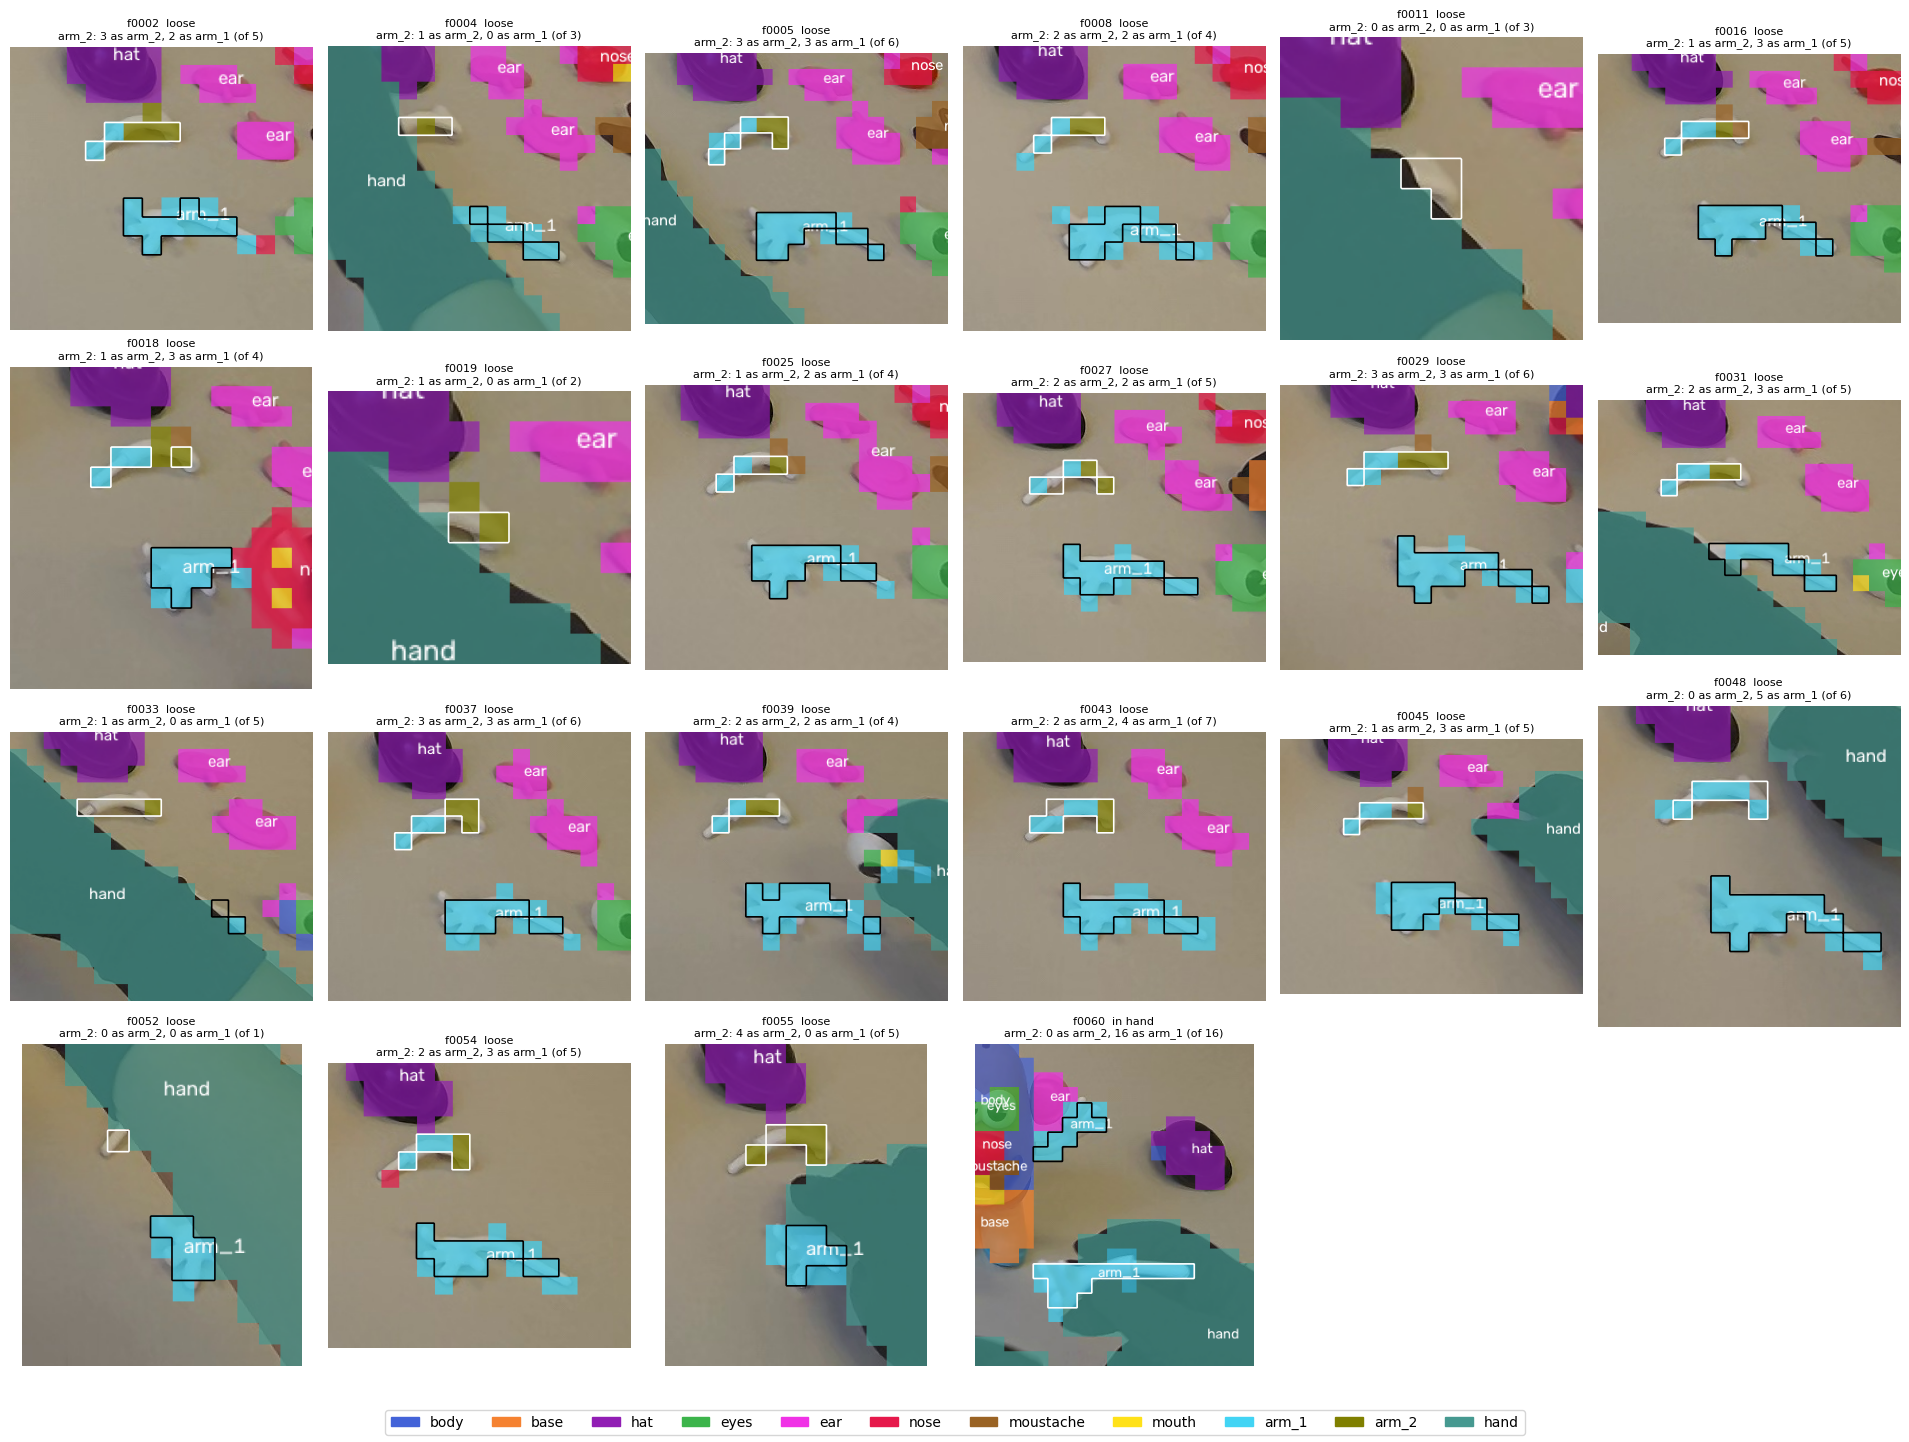

In [12]:
# 4.5 Where A puts arm_1 and arm_2 when arm_2 is loose or in hand (A only, description)
def show_arms(name, frames, cols=6, pad=4):
    """Crop around both arms (ground truth, plus `pad` patches), labels of support set `name` coloured,
    true contours on top: white = arm_2, black = arm_1."""
    rows = int(np.ceil(len(frames) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.6 * rows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, k in zip(axes.flat, frames):
        item = EVAL_FRAMES[k]
        image = np.asarray(Image.open(item["image_path"]).convert("RGB"))
        labels = item["labels"][name]
        overlay = render_overlay(image, labels, MIN_BLOB_PATCHES)

        r, c = np.where(np.isin(item["gt"], [ARM_1, ARM_2]))
        r0, r1 = max(r.min() - pad, 0), min(r.max() + pad + 1, item["gt"].shape[0])
        c0, c1 = max(c.min() - pad, 0), min(c.max() + pad + 1, item["gt"].shape[1])
        ax.imshow(overlay[r0 * PATCH_SIZE:r1 * PATCH_SIZE, c0 * PATCH_SIZE:c1 * PATCH_SIZE])
        for cls, color in ((ARM_2, "white"), (ARM_1, "black")):
            mask = (item["gt"] == cls)[r0:r1, c0:c1]
            if mask.any():
                ax.contour(np.kron(mask, np.ones((PATCH_SIZE, PATCH_SIZE))), levels=[0.5], colors=color, linewidths=1.2)

        on_arm_2 = labels[item["gt"] == ARM_2]
        ax.set_title(f"{item['frame'][-5:]}  {item['states']['arm_2']}\n"
                     f"arm_2: {(on_arm_2 == ARM_2).sum()} as arm_2, {(on_arm_2 == ARM_1).sum()} as arm_1 "
                     f"(of {on_arm_2.size})", fontsize=8)
    legend = [mpatches.Patch(color=CLASS_COLORS[c], label=c) for c in CLASS_NAMES if c != BACKGROUND_LABEL]
    fig.legend(handles=legend, loc="lower center", ncol=11)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    return fig


fig = show_arms("A", EARLY)
fig.savefig(OUTPUT_DIR / "arms_early_A.png", dpi=90, bbox_inches="tight")
plt.show()

Observation 4.4: In the 22 frames where arm_2 is loose or in hand, arm_2 has 112 patches. A labels 35 of them arm_2 and 59 arm_1. Loose, arm_2 covers between 1 and 7 patches, and A gives it between 0 and 4 patches of its own label. In hand (f0060) it covers 16 patches, all labelled arm_1.

Observation 4.5: Loose, arm_2 lies far from the camera, near the hat, and is smaller than arm_1. The patches labelled arm_2 are its closed hand, checked on the frames by the author; the rest of the arm is labelled arm_1, a few patches moustache, none base. No patch of arm_1 is labelled arm_2. In f0011, f0019 and f0052 arm_2 is almost covered by the hand. In f0060 the arm is held close to the camera and turned upwards, and the whole arm, closed hand included, is labelled arm_1.

Interpretation, as a hypothesis. A recognizes the closed hand of arm_2 only from far away: its examples of arm_2 have 3 or 4 patches each, while its largest arm example, arm_1 of caos_f0149 with 16 patches, wins whenever an arm is close (support-set study on V2, Observation 8.5). Counting frames where arm_2 is seen would give f0060 the weight of one frame in 22; counting patches gives it 16 in 112, which is why condition 1 counts patches.

Expectation for Section 5, written before it is run. In assembly_2 arm_2 is picked and mounted at working distance (f0063, f0065), so Hart should add patches of arm_2 seen close, and f0060 should be the frame of assembly_1 that gains most.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4:

configs/assembly_1_events.json: touch, first_seen, insert and hands_off of every piece.

Phase 1 test, Section 3: the rules that chose the frames; f0031 as the join in hand.

Support-set study on V2, Observation 8.2: the mIoU of A on assembly_2, 0.779.

Piaggio et al. 2012, eAppendix ("Choice of the noninferiority margin Δ"): the margin is justified on statistical and practical grounds and fixed in advance.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 5 - Hart on assembly_2

The candidates are every patch of the 10 pieces in the 32 source frames, with its annotated class. They are taken frame by frame in time order, and in row order within a frame.

The similarity of every candidate with each class of A is computed once. When a patch is added to the store, only the column of its class can change, so it is updated with the similarity to that one patch. The result is the same as classifying with the whole store each time, and Section 6.2 checks it on the whole frames.

Hart is applied as written (1968, p. 515), with the store starting from A. A candidate classified wrongly is added; the passes are repeated over the candidates not yet in the store until a whole pass adds nothing. At margin 0 the label of V2 is the class with the highest similarity, and an exact tie goes to the first class, as in assign_labels.

For every patch added, the table keeps its frame, its moment, the label it had when it was added, its pass, and whether it lies inside the piece or on its border.

In [13]:
# 5.1 Candidates: every patch of the 10 pieces in the 32 source frames, in time order and row order
assert DELTA is not None, "Fix DELTA in Section 4 and commit before running Hart"
assert MARGIN == 0.0, "Sections 5-6 classify by argmax, which equals assign_labels only at margin 0"
PIECE_IDS = [CLASS_NAMES.index(p) for p in PIECES]

cand_vectors, cand_rows = [], []
for item in SOURCE_FRAMES:
    rows_, cols_ = np.nonzero(np.isin(item["gt"], PIECE_IDS))      # row order within the frame
    cand_vectors.append(l2_normalize(item["features"])[rows_, cols_])
    for r, c in zip(rows_, cols_):
        label = int(item["gt"][r, c])
        cand_rows.append({"frame": item["frame"], "moment": item["moment"], "row": int(r), "col": int(c),
                          "class": CLASS_NAMES[label], "class_id": label, "coverage": float(item["fractions"][r, c, label])})
CAND = pd.DataFrame(cand_rows)
X = torch.as_tensor(np.concatenate(cand_vectors), device=DEVICE)       # (n, D) unit vectors
Y = torch.as_tensor(CAND["class_id"].values, device=DEVICE)

# Similarity of every candidate with each class of A, computed once (n, K)
S_A = torch.as_tensor(class_similarities_gpu(X.cpu().numpy()[:, None, :], *A_GPU)[:, 0, :], device=DEVICE)
CAND["label_A"] = [CLASS_NAMES[i] for i in S_A.argmax(dim=1).cpu().numpy()]
wrong_a = CAND["label_A"] != CAND["class"]
display(pd.DataFrame({"candidates": CAND["class"].value_counts(),
                      "wrong with A": CAND.loc[wrong_a, "class"].value_counts()}).reindex(PIECES).fillna(0).astype(int).T)
print(f"{len(CAND)} candidates, {int(wrong_a.sum())} labelled wrongly by A")

class,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2
candidates,1297,784,535,249,295,185,215,129,262,167
wrong with A,83,22,30,7,17,15,23,35,19,102


4118 candidates, 353 labelled wrongly by A


In [14]:
# 5.2 Hart (1968, p. 515), starting from A
best = S_A.clone()                                   # best similarity of each candidate with each class of the store
in_store = np.zeros(len(CAND), dtype=bool)
added, added_pass, added_label = [], [], []
n_pass, start = 0, time.time()
while True:
    n_pass += 1
    added_now = 0
    for i in range(len(CAND)):
        if in_store[i]:
            continue
        predicted = int(best[i].argmax())            # first index on ties, as assign_labels at margin 0
        if predicted != int(Y[i]):
            in_store[i] = True
            added.append(i)
            added_pass.append(n_pass)
            added_label.append(CLASS_NAMES[predicted])
            c = int(Y[i])
            best[:, c] = torch.maximum(best[:, c], X @ X[i])
            added_now += 1
    print(f"pass {n_pass}: {added_now} patches added")
    if added_now == 0:
        break
assert bool((best.argmax(dim=1) == Y).all()), "Hart must end with every candidate classified correctly"
print(f"Hart: {len(added)} patches added in {n_pass} passes, {time.time() - start:.0f} s")

HART = CAND.iloc[added].reset_index().rename(columns={"index": "candidate"})
HART["pass"], HART["label before"] = added_pass, added_label
HART["position"] = np.where(HART["coverage"] == 1.0, "interior", "border")

pass 1: 192 patches added
pass 2: 80 patches added
pass 3: 14 patches added
pass 4: 0 patches added
Hart: 286 patches added in 4 passes, 1 s


In [15]:
# 5.3 What Hart added: label it had, moment, border or interior, pass; arm_2 by frame
for columns in ("label before", "moment", "position", "pass"):
    display(pd.crosstab(HART["class"], HART[columns]).reindex(index=PIECES).fillna(0).astype(int))
print("arm_2 patches added, by frame:")
display(HART[HART["class"] == "arm_2"].groupby(["frame", "moment"]).size().to_frame("added"))

label before,arm_1,arm_2,background,base,body,ear,eyes,hand,hat,moustache,mouth,nose
class,,,,,,,,,,,,
body,0,0,1,17,0,8,32,4,1,12,6,12
base,0,0,1,0,14,0,0,0,2,2,4,0
hat,0,0,1,0,2,4,0,0,0,0,0,0
eyes,0,0,0,0,25,0,0,0,0,0,0,0
ear,1,0,0,1,9,0,0,0,2,0,0,2
nose,0,0,0,0,13,0,0,0,1,8,1,0
moustache,0,0,0,1,14,0,0,0,0,0,12,12
mouth,0,0,0,8,6,1,0,0,0,9,0,3
arm_1,0,16,1,0,0,0,0,0,0,0,0,0


moment,mount,pick,table
class,,,
body,37,37,19
base,5,7,11
hat,4,2,1
eyes,7,13,5
ear,5,7,3
nose,8,4,11
moustache,13,9,17
mouth,8,10,9
arm_1,10,3,4


position,border,interior
class,,
body,82,11
base,21,2
hat,7,0
eyes,18,7
ear,15,0
nose,23,0
moustache,38,1
mouth,24,3
arm_1,17,0


pass,1,2,3
class,,,
body,63,24,6
base,15,7,1
hat,5,2,0
eyes,14,9,2
ear,11,3,1
nose,15,7,1
moustache,22,15,2
mouth,20,7,0
arm_1,15,2,0


arm_2 patches added, by frame:


,,added
frame,moment,
assembly_2_f0003,table,1
assembly_2_f0005,mount,3
assembly_2_f0012,mount,2
assembly_2_f0030,mount,1
assembly_2_f0033,mount,2
assembly_2_f0042,pick,1
assembly_2_f0052,table,1
assembly_2_f0054,mount,1
assembly_2_f0059,pick,2


Observation 5.1: The 32 source frames give 4,118 candidates. A labels 353 of them wrongly. arm_2 is by far the worst, 102 of 167 patches (61%), then the mouth, 35 of 129 (27%); the other pieces lie between 2.8% (base and eyes) and 10.7% (moustache).

Observation 5.2: Hart adds 286 patches in 4 passes, 192, 80 and 14, and the fourth adds none. Every candidate is then classified correctly. The added patches are 6.9% of the candidates, and the store grows from 39,125 to 39,411 prototypes. The run takes about 1 s.

Observation 5.3: The body receives most patches (93), then the moustache (39), the mouth (27), the eyes (25), nose and base (23 each), the two arms (17 each), the ear (15) and the hat (7). The patches added to the body were labelled eyes (32), base (17), moustache (12) and nose (12): they lie where the body meets the face pieces and the base. The patches added to the mouth were labelled moustache (9), base (8) and body (6).

The two arms correct each other. Of the 17 patches added to arm_2, 15 were labelled arm_1; of the 17 added to arm_1, 16 were labelled arm_2. On the same frames A labelled only 3 patches of arm_1 as arm_2 (support-set study on V2, Observation 8.5), so at least 13 patches of arm_1 became arm_2 after patches of arm_2 had been added, and Hart corrected them in turn.

Of the 17 patches of arm_2, only 2 come from the arm seen close, at its pick (f0063); none from its mounting (f0065). The others come from arm_2 lying loose in the frames of other events. The expectation of Section 4 holds only in part.

Almost every added patch is partly covered by its piece: 262 of 286. Only body (11), eyes (7), mouth (3), base (2) and moustache (1) receive patches fully inside the piece. The added patches come from all three moments: 106 at the mounting, 98 at the pick, 82 at the table.

Interpretation, as a hypothesis. Hart adds the patches that lie at the boundary between classes, as condensation is expected to do (García et al. 2012, Sect. 3.1.2). For thin pieces such as the arms, almost no patch is fully covered at this scale, so "border" here also means "thin".

------------------------------------------------------------------------------------------------------------------------------------------

References Section 5:

Hart 1968, p. 515: the condensed nearest neighbour rule, with STORE and GRABBAG, repeated until a pass transfers nothing.

García et al. 2012, Sect. 3.1.1: incremental search and the importance of the order of presentation.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 6 - Gates reduction

Gates (1972, p. 432) starts from the set of Hart and removes one example at a time. The removal is kept if every candidate is still classified correctly, and undone otherwise. Here only the patches added by Hart can be removed, in the order in which they were added; A is never touched.

Two support sets come out. H is A plus every patch added by Hart, measured only as a description. G is A plus the patches kept by Gates, the one judged by the decision rule. Both must classify correctly every patch of the pieces in the 32 source frames, checked by running V2 on the whole frames. Both are saved.

In [16]:
# 6.1 Gates (1972, p. 432) on the patches added by Hart only, in the order of Hart
added_idx = torch.as_tensor(added, device=DEVICE)
M = X @ X[added_idx].T                               # (n, m): similarity of each candidate with each added patch
added_class = Y[added_idx]
keep = torch.ones(len(added), dtype=torch.bool, device=DEVICE)
best_current = best.clone()                          # store = A + every added patch (end of Hart)

start = time.time()
for j in range(len(added)):
    c = int(added_class[j])
    keep[j] = False
    others = keep & (added_class == c)
    column = torch.maximum(S_A[:, c], M[:, others].max(dim=1).values) if bool(others.any()) else S_A[:, c]
    trial = best_current.clone()
    trial[:, c] = column
    if bool((trial.argmax(dim=1) == Y).all()):
        best_current = trial                         # removal kept
    else:
        keep[j] = True                               # removal undone
assert bool((best_current.argmax(dim=1) == Y).all())
HART["kept by Gates"] = keep.cpu().numpy()
print(f"Gates: {int(keep.sum())} of {len(added)} patches kept, {time.time() - start:.0f} s")
display(pd.DataFrame({"Hart": HART["class"].value_counts(),
                      "Gates": HART.loc[HART["kept by Gates"], "class"].value_counts()}).reindex(PIECES).fillna(0).astype(int).T)

Gates: 248 of 286 patches kept, 0 s


class,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2
Hart,93,23,7,25,15,23,39,27,17,17
Gates,81,20,5,23,14,20,32,21,16,16


In [17]:
# 6.2 Support sets H and G as V2 prototypes, checked on the whole source frames, and saved
from perception.prototypes import save_patch_prototypes


def support_set(rows):
    """A plus the candidates `rows`, sorted by class; returns vectors, owners and their GPU copies."""
    vectors = np.concatenate([A_VECTORS, X[torch.as_tensor(rows, device=DEVICE)].cpu().numpy()])
    owners = np.concatenate([A_OWNERS, CAND["class_id"].values[rows]])
    vectors, owners = sort_by_class(vectors, owners)
    return vectors, owners, tuple(torch.as_tensor(x, device=DEVICE) for x in (vectors, owners))


SUPPORT = {"A": (A_VECTORS, A_OWNERS, A_GPU),
           "H": support_set(np.array(added)),
           "G": support_set(np.array(added)[HART["kept by Gates"].values])}

for name, rule in (("H", "Hart 1968 from A"), ("G", "Hart 1968 from A, reduced by Gates 1972 on the added patches")):
    wrong = 0
    for item in SOURCE_FRAMES:
        labels = assign_labels(class_similarities_gpu(item["features"], *SUPPORT[name][2]), MARGIN)
        is_piece = np.isin(item["gt"], PIECE_IDS)
        wrong += int((labels[is_piece] != item["gt"][is_piece]).sum())
    print(f"{name}: {len(SUPPORT[name][1])} prototypes ({len(SUPPORT[name][1]) - len(A_OWNERS)} added); "
          f"piece patches of the source frames labelled wrongly: {wrong}")
    assert wrong == 0
    save_patch_prototypes(OUTPUT_DIR / f"patch_prototypes_{name}.npz", SUPPORT[name][0], SUPPORT[name][1],
                          {"support_set": name, "rule": rule, "base": f"{PROTOTYPES_PATH.name} (SHA-256 {fingerprint})",
                           "source": "assembly_2, 32 annotated frames", "margin": MARGIN,
                           "min_label_coverage": MIN_LABEL_COVERAGE, "added": len(SUPPORT[name][1]) - len(A_OWNERS)})

H: 39411 prototypes (286 added); piece patches of the source frames labelled wrongly: 0
G: 39373 prototypes (248 added); piece patches of the source frames labelled wrongly: 0


Observation 6: Gates keeps 248 of the 286 patches added by Hart and removes 38. The body goes from 93 to 81, the moustache from 39 to 32, the mouth from 27 to 21, base and nose from 23 to 20, the eyes from 25 to 23, the hat from 7 to 5, the ear from 15 to 14, and each arm from 17 to 16.

H has 39,411 prototypes and G 39,373. Run on the whole source frames with the function of the pipeline, both label every patch of the pieces correctly, so the computation of Sections 5 and 6 is the same as V2.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 6:

Gates 1972, p. 432: the reduced nearest neighbour rule, which removes one example at a time and puts it back if any training example becomes wrong; pp. 432-433: it finds the minimal consistent subset when the set of Hart contains it.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 7 - Decision on assembly_1

This is the only use of assembly_1 to judge a new support set. The rule, the margin and the support set G were fixed before this section was run.

H and G classify the 31 evaluation frames, and their labels are saved. G is compared with A by the three conditions of Section 1. The intervals come from the same resamples for both support sets: blocks of 3 consecutive frames, 1000 resamples, seed 0.

H is measured with the same code in Section 8, as a description.

In [18]:
# 7.1 Labels of the 31 evaluation frames with H and G (A from Section 3.3), saved
for item in EVAL_FRAMES:
    for name in ("H", "G"):
        item["labels"][name] = assign_labels(class_similarities_gpu(item["features"], *SUPPORT[name][2]), MARGIN)
for name in ("H", "G"):
    CONF[name] = [confusion_matrix(item["gt"], item["labels"][name]) for item in EVAL_FRAMES]
np.savez_compressed(OUTPUT_DIR / "evaluation_labels.npz", frames=np.array([item["frame"] for item in EVAL_FRAMES]),
                    **{f"{item['frame']}__{name}": item["labels"][name].astype(np.int64)
                       for item in EVAL_FRAMES for name in ("A", "H", "G")})
print("Labels of A, H and G saved")

Labels of A, H and G saved


In [19]:
# 7.2 Decision rule (Section 1): G against A, paired block bootstrap on the same resamples
n = len(EVAL_FRAMES)
rng = np.random.default_rng(RANDOM_SEED)
starts = rng.integers(0, n - BLOCK + 1, size=(N_BOOTSTRAP, int(np.ceil(n / BLOCK))))
RESAMPLES = np.array([np.concatenate([np.arange(s, s + BLOCK) for s in row])[:n] for row in starts])
PIECE_IDX = [CLASS_NAMES.index(p) for p in PIECES]


def compare(name):
    """The three conditions of the decision rule for support set `name` against A."""
    # Condition 1: patches of arm_2 labelled arm_2 where arm_2 is loose or in hand
    hits_a, hits_new = arm_2_hits("A"), arm_2_hits(name)
    low, high = percentile_interval((hits_new - hits_a)[RESAMPLES].sum(axis=1))
    c1 = {"A": int(hits_a.sum()), name: int(hits_new.sum()), "difference": int(hits_new.sum() - hits_a.sum()),
          "95% low": low, "95% high": high}

    # Condition 2: frames where A sees a piece and the new support set does not (gains as description)
    changes = [{"piece": p, "state": s, "frame": item["frame"],
                "A": seen(item, item["labels"]["A"], p), name: seen(item, item["labels"][name], p)}
               for item in EVAL_FRAMES for p, s in item["states"].items()]
    changes = pd.DataFrame(changes)
    losses = changes[changes["A"] & ~changes[name]]
    gains = changes[~changes["A"] & changes[name]]

    # Condition 3: IoU of every piece and mIoU over the 10 pieces, lower end above -DELTA
    iou_a, iou_new = frame_iou(CONF["A"], EXCLUDED), frame_iou(CONF[name], EXCLUDED)
    diff = bootstrap_class_iou(CONF[name], EXCLUDED, RESAMPLES) - bootstrap_class_iou(CONF["A"], EXCLUDED, RESAMPLES)
    lows, highs = percentile_interval(diff)
    rows = {p: {"A": iou_a[i], name: iou_new[i], "difference": iou_new[i] - iou_a[i], "95% low": lows[i], "95% high": highs[i]}
            for p, i in zip(PIECES, PIECE_IDX)}
    m_low, m_high = percentile_interval(bootstrap_miou(CONF[name], EXCLUDED, RESAMPLES) - bootstrap_miou(CONF["A"], EXCLUDED, RESAMPLES))
    m_a, m_new = frame_miou(CONF["A"], EXCLUDED), frame_miou(CONF[name], EXCLUDED)
    rows["mIoU, 10 pieces"] = {"A": m_a, name: m_new, "difference": m_new - m_a, "95% low": m_low, "95% high": m_high}
    c3 = pd.DataFrame(rows).T
    c3["not worse than -Δ"] = c3["95% low"] > -DELTA

    passed = {"1: arm_2 better": c1["95% low"] > 0, "2: no frame lost": len(losses) == 0,
              "3: every IoU not worse than -Δ": bool(c3["not worse than -Δ"].all())}
    return c1, losses, gains, c3, passed


C1, LOSSES, GAINS, C3, PASSED = compare("G")
print("Condition 1, patches of arm_2 labelled arm_2 (loose or in hand):", {k: (round(v, 1) if isinstance(v, float) else v) for k, v in C1.items()})
print(f"Condition 2: {len(LOSSES)} frames lost, {len(GAINS)} gained")
display(LOSSES)
display(GAINS)
print(f"Condition 3 (Δ = {DELTA}):")
display(C3.round(3))
for k, v in PASSED.items():
    print(f"{k}: {v}")
DECISION = "keep G" if all(PASSED.values()) else "keep A"
print("Decision:", DECISION)

Condition 1, patches of arm_2 labelled arm_2 (loose or in hand): {'A': 35, 'G': 91, 'difference': 56, '95% low': np.float64(37.0), '95% high': np.float64(82.0)}
Condition 2: 0 frames lost, 6 gained


,piece,state,frame,A,G


,piece,state,frame,A,G
32,mouth,loose,assembly_1_f0008,False,True
176,moustache,mounted,assembly_1_f0047,False,True
188,arm_2,loose,assembly_1_f0048,False,True
236,arm_2,in hand,assembly_1_f0060,False,True
239,hat,loose,assembly_1_f0062,False,True
246,arm_2,mounting,assembly_1_f0062,False,True


Condition 3 (Δ = 0.014):


,A,G,difference,95% low,95% high,not worse than -Δ
body,0.864,0.858,-0.007,-0.052,0.035,False
base,0.909,0.936,0.027,-0.010,0.071,True
hat,0.905,0.888,-0.017,-0.098,0.056,False
eyes,0.815,0.769,-0.047,-0.100,0.012,False
ear,0.892,0.933,0.040,0.015,0.075,True
nose,0.721,0.811,0.090,0.027,0.154,True
moustache,0.766,0.803,0.037,-0.024,0.094,False
mouth,0.626,0.710,0.084,-0.047,0.220,False
arm_1,0.733,0.727,-0.006,-0.073,0.084,False
arm_2,0.416,0.640,0.224,0.112,0.366,True


1: arm_2 better: True
2: no frame lost: True
3: every IoU not worse than -Δ: False
Decision: keep A


In [20]:
# 7.3 Decision saved
(OUTPUT_DIR / "decision.json").write_text(json.dumps({
    "decision": DECISION, "delta": DELTA, "conditions": {k: bool(v) for k, v in PASSED.items()},
    "condition_1": {k: float(v) for k, v in C1.items()}, "frames_lost": LOSSES.to_dict("records"),
    "support_sets": {"A": len(A_OWNERS), "H": len(SUPPORT["H"][1]), "G": len(SUPPORT["G"][1])},
    "run": time.strftime("%Y-%m-%d %H:%M")}, indent=2, default=str))
print("Saved", OUTPUT_DIR / "decision.json")

Saved c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_support_set_hart\decision.json


Observation 7: Condition 1 holds. Where arm_2 is loose or in hand, G labels 91 of its patches arm_2 against 35 for A, a difference of 56 with a 95% interval of [37, 82]. The IoU of arm_2 rises from 0.416 to 0.640 (+0.224, [0.112, 0.366]), while arm_1 stays at 0.727 against 0.733.

Condition 2 holds. No piece loses a frame in any state, and 6 frames are gained: arm_2 in hand (f0060), at the mounting (f0062) and loose (f0048), the mouth loose (f0008), the hat loose (f0062) and the moustache mounted (f0047).

Condition 3 fails. The mIoU over the 10 pieces rises from 0.765 to 0.807 (+0.043, [0.014, 0.077]). Ear, nose and arm_2 are clearly better, and base is not worse than −Δ. For body, hat, eyes, moustache, mouth and arm_1 the lower end of the interval lies below −0.014, between −0.024 (moustache) and −0.100 (eyes). Their differences are −0.007, −0.017, −0.047, +0.037, +0.084 and −0.006, and their intervals are between about 0.08 and 0.27 wide, against a margin of 0.014.

Decision: by the rule of Section 1, A is kept.

The rule fails for lack of precision rather than for evidence of a loss: with 31 frames the intervals are several times wider than the margin, a risk written in Section 4. A small margin needs many more observations (Piaggio et al. 2012, eAppendix, "Design"). The only piece whose estimate falls clearly is the eyes (−0.047); as a hypothesis, the 32 patches of the body added where the body had been labelled eyes (Observation 5.3) take part of the eyes. The rule and the margin are not changed after this result.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 7:

Koehn 2004, Sect. 6: paired bootstrap resampling to compare two systems on the same samples.

Künsch 1989, Sect. 2.3: resamples made of blocks of consecutive observations.

Piaggio et al. 2012, eAppendix ("Interpretation"): non-inferiority is shown when the interval lies entirely on the right side of the margin.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 8 - Description: H, the pieces by state, the arms, the eyes, how many patches, the video

Nothing in this section changes the decision of Section 7. It describes what G and H do, to understand the result and to prepare the next test.

H, A plus every patch added by Hart, is measured with the same code as G. For Phase 2, the patches of every piece in every frame and state are counted with A, G and H and saved. The arms are shown with G as they were shown with A in Section 4.5. The eyes, the only piece whose IoU falls clearly with G, are shown where G adds most errors.

The question of how many patches are needed is answered as a description. The patches kept by Gates are added to A in blocks of 10, in the order of Hart, and the measures are recomputed at each step on assembly_1. This is not a choice: choosing the number of patches on these frames would be a selection on the evaluation set.

Finally, the whole video of assembly_1 is labelled frame by frame with A and with G, side by side, and the labels of every frame are saved for Phase 2.

Finally, the errors of A on the source frames are traced back to the prototypes that cause them. For every patch of assembly_2 that A labels wrongly, the winning prototype is the most similar prototype of the wrong class; its reference frame and position are recovered from the annotations, in the order in which the pipeline built A. This only describes A; nothing is removed.

In [20]:
# 8.1 H against A with the measures of Section 7 (description, no decision), next to G
C1_H, LOSSES_H, GAINS_H, C3_H, PASSED_H = compare("H")
print("Condition 1, patches of arm_2 labelled arm_2:", {k: (round(v, 1) if isinstance(v, float) else v) for k, v in C1_H.items()})
print(f"Condition 2: {len(LOSSES_H)} frames lost, {len(GAINS_H)} gained")
display(LOSSES_H)
display(pd.DataFrame({"A": C3["A"], "G": C3["G"], "H": C3_H["H"],
                      "H 95% low": C3_H["95% low"], "H 95% high": C3_H["95% high"]}).round(3))
print("H against the rule (description only):", PASSED_H)

Condition 1, patches of arm_2 labelled arm_2: {'A': 35, 'H': 91, 'difference': 56, '95% low': np.float64(37.0), '95% high': np.float64(82.0)}
Condition 2: 0 frames lost, 7 gained


,piece,state,frame,A,H


,A,G,H,H 95% low,H 95% high
body,0.864,0.858,0.865,-0.041,0.040
base,0.909,0.936,0.943,0.001,0.076
hat,0.905,0.888,0.876,-0.108,0.053
eyes,0.815,0.769,0.781,-0.084,0.022
ear,0.892,0.933,0.936,0.015,0.080
nose,0.721,0.811,0.828,0.040,0.183
moustache,0.766,0.803,0.807,-0.019,0.096
mouth,0.626,0.710,0.711,-0.027,0.201
arm_1,0.733,0.727,0.729,-0.071,0.087
arm_2,0.416,0.640,0.640,0.112,0.366


H against the rule (description only): {'1: arm_2 better': np.True_, '2: no frame lost': True, '3: every IoU not worse than -Δ': False}


In [21]:
# 8.2 For Phase 2: patches of every piece in every frame and state, right and most confused, with A, G and H (saved)
records = []
for item in EVAL_FRAMES:
    for p, s in item["states"].items():
        c = CLASS_NAMES.index(p)
        true = item["gt"] == c
        rec = {"frame": item["frame"], "piece": p, "state": s, "patches": int(true.sum())}
        for name in ("A", "G", "H"):
            lab = item["labels"][name][true]
            rec[f"{name} right"] = int((lab == c).sum())
            others = pd.Series([CLASS_NAMES[x] for x in lab[lab != c]], dtype=object).value_counts()
            rec[f"{name} most confused"] = f"{others.index[0]} ({others.iloc[0]})" if len(others) else ""
        records.append(rec)
PATCH_COUNTS = pd.DataFrame(records)
PATCH_COUNTS.to_csv(OUTPUT_DIR / "patch_counts_by_piece_and_state.csv", index=False)
summary = PATCH_COUNTS.groupby(["piece", "state"])[["patches", "A right", "G right", "H right"]].sum()
display(summary.reindex(PIECES, level=0))

patches  A right  G right  H right
piece     state                                       
body      in hand        62       46       55       55
          loose          26       26       26       26
          mounted      1072     1004     1011     1015
          mounting       51       40       49       49
base      in hand        55       52       55       55
          mounted       708      690      698      699
          mounting       53       48       52       52
hat       in hand        10        1        7        7
          loose         442      426      439      440
          mounted        15       15       15       15
          mounting       13       13       13       13
eyes      in hand         7        1        1        1
          loose         136      116      105      105
          mounted       155      139      136      136
          mounting        9        9        4        7
ear       in hand        16       13       14       13
          loose         225      225      222      222
          mounted       126      112      117      117
          mounting       11        7        9       11
nose      in hand        17       15       16       16
          loose          55       46       54       54
          mounted       128      114      120      121
          mounting        9        6        7        7
moustache in hand        29       27       28       29
          loose          52       49       52       52
          mounted       120      100      110      109
          mounting        2        1        2        2
mouth     in hand        18        2       11       11
          loose           7        4        7        7
          mounted        86       80       79       82
          mounting        7        6        6        6
arm_1     in hand         6        6        6        6
          loose         193      190      172      172
          mounted        40       39       40       40
          mounting        9        9        8        8
arm_2     in hand        16        0       13       13
          loose          96       35       78       78
          mounted        22       22       21       21
          mounting        3        0        2        2

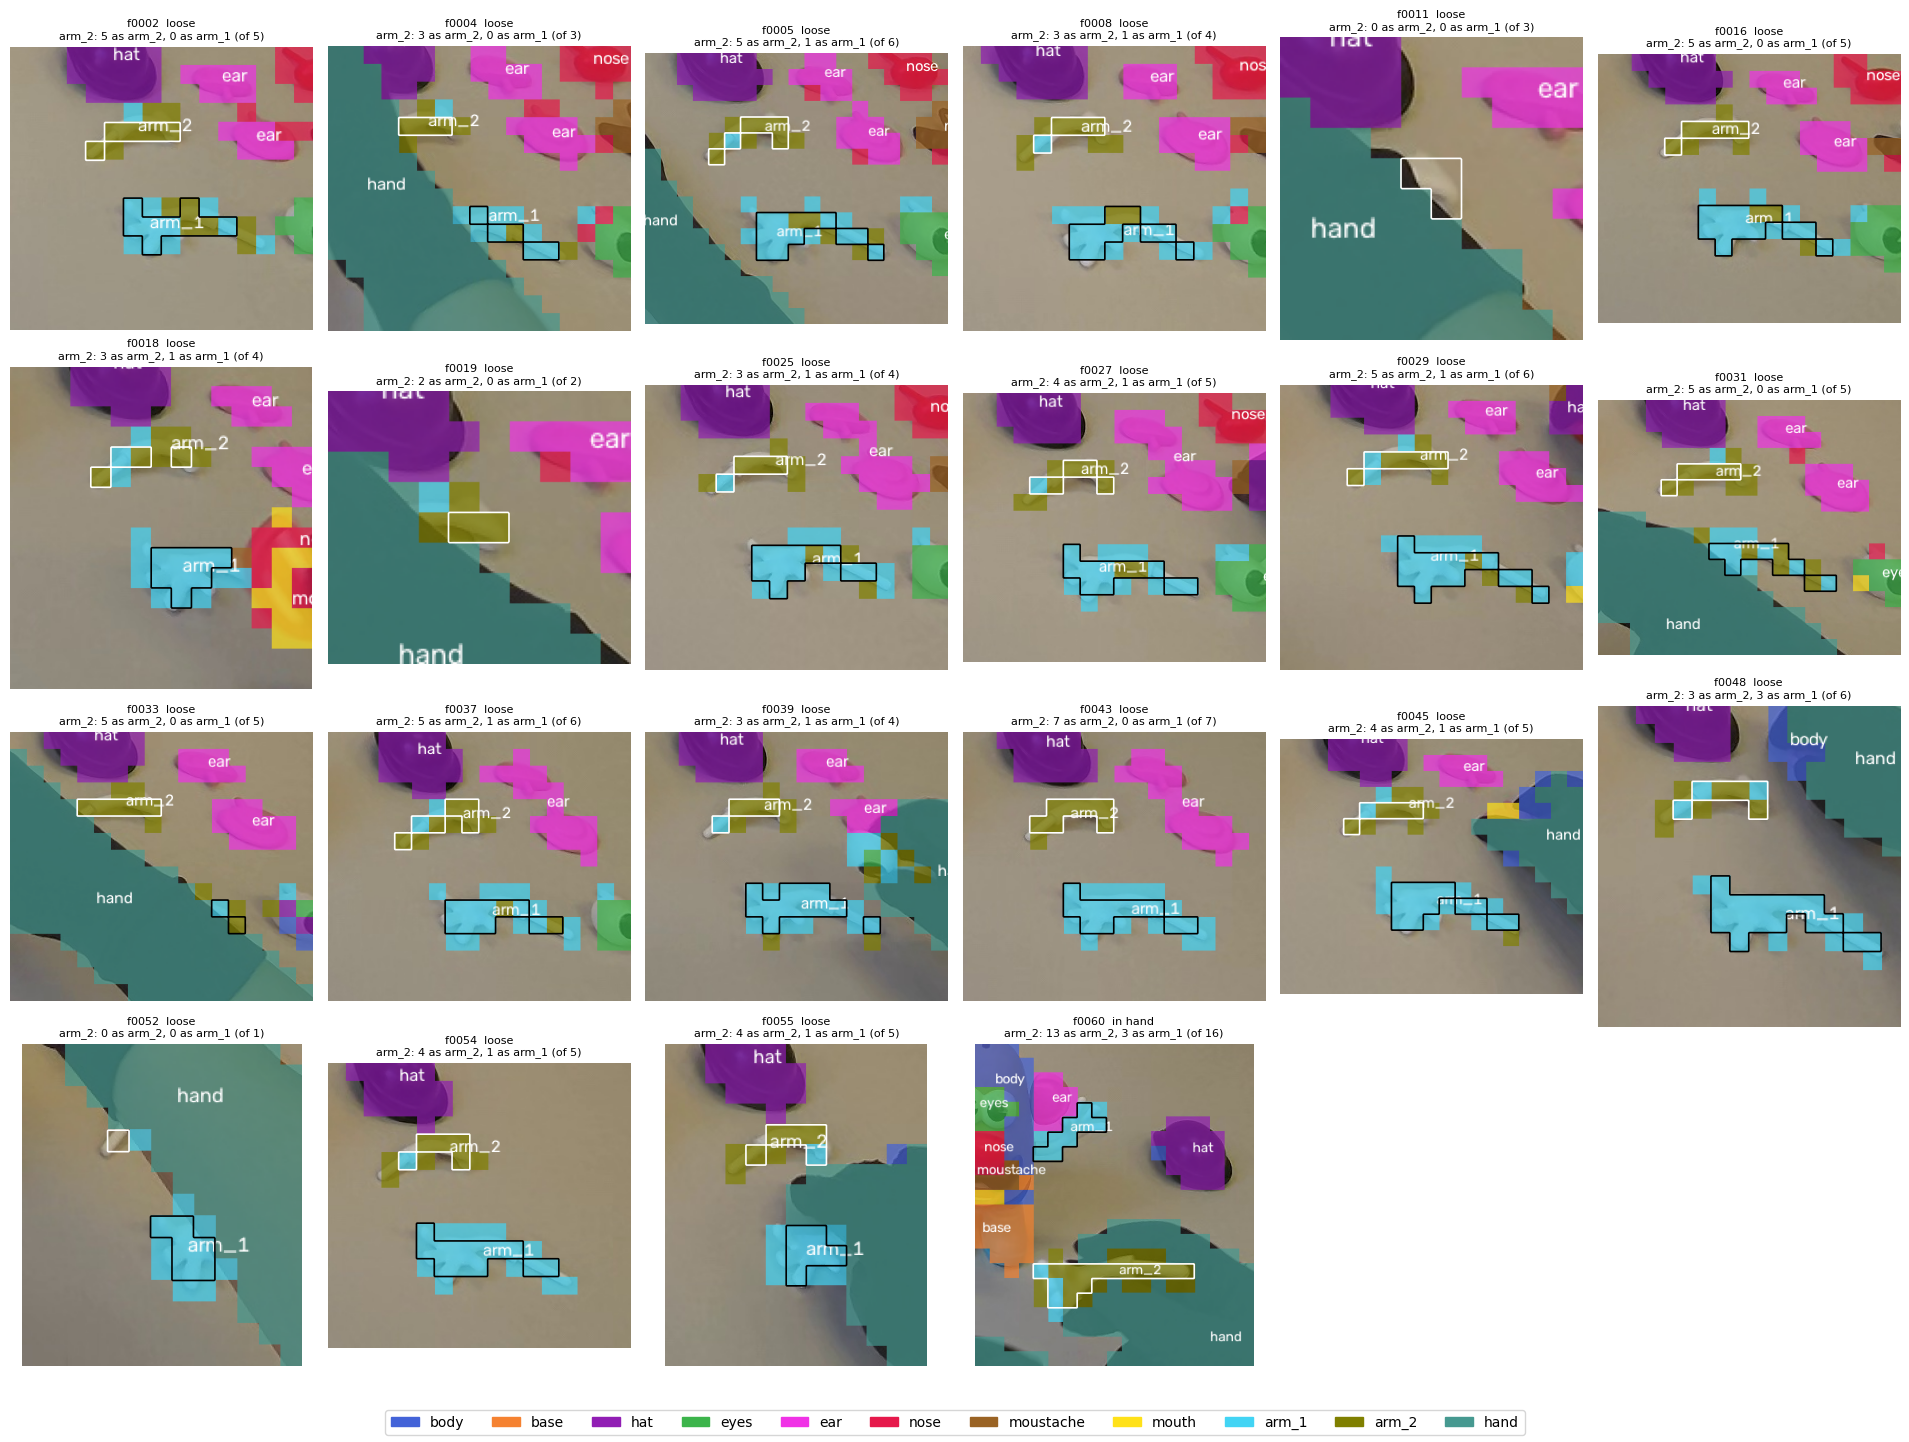

In [23]:
# 8.3 Where G puts arm_1 and arm_2 when arm_2 is loose or in hand (same figure as 4.5)
fig = show_arms("G", EARLY)
fig.savefig(OUTPUT_DIR / "arms_early_G.png", dpi=90, bbox_inches="tight")
plt.show()

A: eyes right 265; eyes patches labelled as {'background': 8, 'body': 18, 'ear': 10, 'mouth': 2, 'arm_1': 4}; labelled eyes but are {'body': 15, 'hand': 3}
G: eyes right 246; eyes patches labelled as {'background': 3, 'body': 25, 'hat': 5, 'ear': 1, 'nose': 4, 'mouth': 4, 'arm_1': 14, 'arm_2': 5}; labelled eyes but are {'body': 11, 'hand': 2}


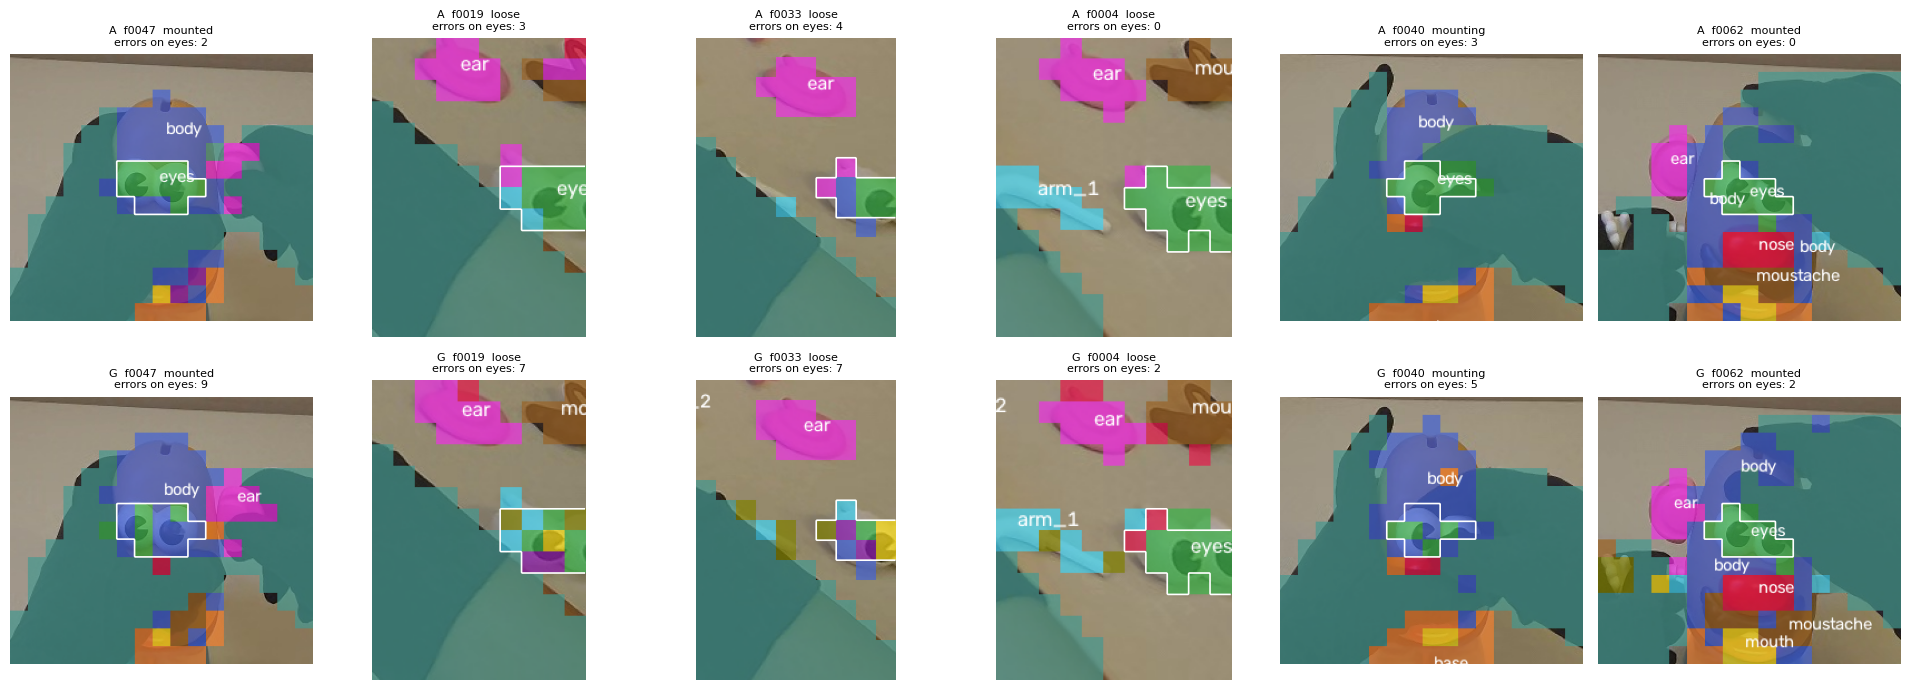

In [22]:
# 8.4 The eyes with A and G: where their patches go, and the 6 frames where G adds most errors (description)
EYES = CLASS_NAMES.index("eyes")
for name in ("A", "G"):
    total = np.sum(CONF[name], axis=0)
    out_ = {CLASS_NAMES[j]: int(v) for j, v in enumerate(total[EYES]) if v and j != EYES}
    in_ = {CLASS_NAMES[j]: int(v) for j, v in enumerate(total[:, EYES]) if v and j != EYES}
    print(f"{name}: eyes right {int(total[EYES, EYES])}; eyes patches labelled as {out_}; labelled eyes but are {in_}")


def eye_errors(k, name):
    """Missed eye patches plus patches wrongly labelled eyes (ignored ground truth skipped), in frame k."""
    item = EVAL_FRAMES[k]
    true, pred, valid = item["gt"] == EYES, item["labels"][name] == EYES, item["gt"] != IGNORE_ID
    return int((true & ~pred).sum() + (pred & ~true & valid).sum())


with_eyes = [k for k, item in enumerate(EVAL_FRAMES) if "eyes" in item["states"]]
worst = sorted(with_eyes, key=lambda k: eye_errors(k, "G") - eye_errors(k, "A"), reverse=True)[:6]

fig, axes = plt.subplots(2, len(worst), figsize=(3.2 * len(worst), 7))
for col, k in enumerate(worst):
    item = EVAL_FRAMES[k]
    image = np.asarray(Image.open(item["image_path"]).convert("RGB"))
    r, c = np.where(item["gt"] == EYES)
    r0, r1 = max(r.min() - 6, 0), min(r.max() + 7, 64)
    c0, c1 = max(c.min() - 6, 0), min(c.max() + 7, 64)
    for row, name in enumerate(("A", "G")):
        ax = axes[row, col]
        overlay = render_overlay(image, item["labels"][name], MIN_BLOB_PATCHES)
        ax.imshow(overlay[r0 * PATCH_SIZE:r1 * PATCH_SIZE, c0 * PATCH_SIZE:c1 * PATCH_SIZE])
        mask = (item["gt"] == EYES)[r0:r1, c0:c1]
        ax.contour(np.kron(mask, np.ones((PATCH_SIZE, PATCH_SIZE))), levels=[0.5], colors="white", linewidths=1.2)
        ax.set_title(f"{name}  {item['frame'][-5:]}  {item['states']['eyes']}\nerrors on eyes: {eye_errors(k, name)}", fontsize=8)
        ax.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "eyes_A_vs_G.png", dpi=90, bbox_inches="tight")
plt.show()

,mIoU,arm_2 hits,arm_1,arm_2,eyes,mouth
patches added,,,,,,
0,0.765,35,0.733,0.416,0.815,0.626
10,0.758,25,0.667,0.336,0.809,0.703
20,0.760,25,0.651,0.297,0.803,0.703
30,0.738,25,0.674,0.320,0.803,0.669
40,0.740,24,0.669,0.315,0.803,0.508
50,0.746,24,0.669,0.317,0.803,0.554
60,0.748,27,0.664,0.329,0.803,0.573
70,0.744,28,0.664,0.331,0.797,0.570
80,0.729,28,0.664,0.331,0.666,0.573


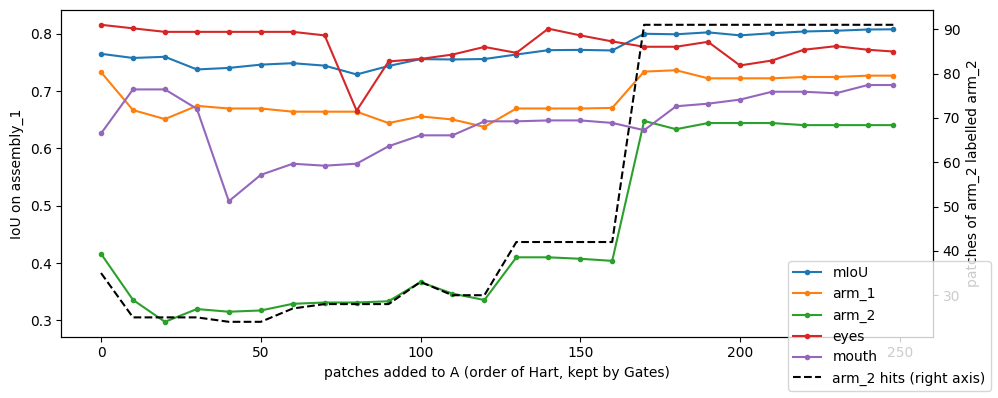

In [23]:
# 8.5 How many patches: the patches kept by Gates added to A in blocks of 10, in the order of Hart (description)
kept_rows = np.array(added)[HART["kept by Gates"].values]
steps = list(range(0, len(kept_rows), 10)) + [len(kept_rows)]
curve = []
for k in steps:
    gpu = support_set(kept_rows[:k])[2] if k else A_GPU
    labels = [assign_labels(class_similarities_gpu(item["features"], *gpu), MARGIN) for item in EVAL_FRAMES]
    conf = [confusion_matrix(item["gt"], lab) for item, lab in zip(EVAL_FRAMES, labels)]
    iou = frame_iou(conf, EXCLUDED)
    hits = sum(int((labels[j][EVAL_FRAMES[j]["gt"] == ARM_2] == ARM_2).sum()) for j in EARLY)
    curve.append({"patches added": k, "mIoU": frame_miou(conf, EXCLUDED), "arm_2 hits": hits,
                  **{p: iou[CLASS_NAMES.index(p)] for p in ("arm_1", "arm_2", "eyes", "mouth")}})
CURVE = pd.DataFrame(curve).set_index("patches added")
display(CURVE.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
for col in ("mIoU", "arm_1", "arm_2", "eyes", "mouth"):
    ax.plot(CURVE.index, CURVE[col], marker=".", label=col)
ax.set_xlabel("patches added to A (order of Hart, kept by Gates)")
ax.set_ylabel("IoU on assembly_1")
ax2 = ax.twinx()
ax2.plot(CURVE.index, CURVE["arm_2 hits"], color="black", linestyle="--", label="arm_2 hits (right axis)")
ax2.set_ylabel("patches of arm_2 labelled arm_2")
fig.legend(loc="lower right")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "curve_patches_added.png", dpi=90, bbox_inches="tight")
plt.show()

In [26]:
# 8.6 Video of assembly_1, frame by frame: A (left) and G (right); the labels of every frame are saved for Phase 2
cap = cv2.VideoCapture(str(VIDEO_PATH))
fps, n_frames = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
SIDE = 768
output_video = OUTPUT_DIR / "assembly_1_A_vs_G.mp4"
writer = cv2.VideoWriter(str(output_video), cv2.VideoWriter_fourcc(*"mp4v"), fps, (2 * SIDE, SIDE))
video_labels = {"A": [], "G": []}

start = time.time()
for f in range(n_frames):
    ok, frame_bgr = cap.read()
    if not ok:
        break
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    features, size = extractor.extract(Image.fromarray(frame_rgb))
    assert tuple(size) == INPUT_SIZE
    panels = []
    for name in ("A", "G"):
        labels = assign_labels(class_similarities_gpu(features, *SUPPORT[name][2]), MARGIN)
        video_labels[name].append(labels.astype(np.uint8))
        panel = cv2.resize(render_overlay(frame_rgb, labels, MIN_BLOB_PATCHES), (SIDE, SIDE))
        cv2.putText(panel, f"{name}   {f / fps:.1f} s", (15, 35), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2, cv2.LINE_AA)
        panels.append(panel)
    writer.write(cv2.cvtColor(np.hstack(panels), cv2.COLOR_RGB2BGR))
    if (f + 1) % 200 == 0:
        print(f"{f + 1}/{n_frames} frames, {(time.time() - start) / 60:.1f} min")
cap.release()
writer.release()
np.savez_compressed(OUTPUT_DIR / "assembly_1_labels_A_G.npz", fps=fps,
                    **{name: np.stack(v) for name, v in video_labels.items()})
print(f"Done: {f + 1} frames in about {(time.time() - start) / 60:.0f} min -> {output_video}")

200/2348 frames, 2.2 min
400/2348 frames, 4.3 min
600/2348 frames, 6.4 min
800/2348 frames, 8.5 min
1000/2348 frames, 10.6 min
1200/2348 frames, 12.6 min
1400/2348 frames, 14.7 min
1600/2348 frames, 16.7 min
1800/2348 frames, 18.8 min
2000/2348 frames, 20.9 min
2200/2348 frames, 23.0 min
Done: 2348 frames in about 25 min -> c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_support_set_hart\assembly_1_A_vs_G.mp4


Observation 8.1: H gives almost the same values as G. Condition 1 is identical (91 patches against 35). No frame is lost and 7 are gained. The mIoU is 0.812 against 0.807 for G; base is clearly better (0.943, [0.001, 0.076]). Condition 3 fails for H too: the lower end lies below −0.014 for body, hat, eyes, moustache, mouth and arm_1, down to −0.108 (hat). The 38 patches removed by Gates change little.

Observation 8.2: With G, arm_2 in hand has 13 of 16 patches right against 0 with A, and arm_2 loose 78 of 96 against 35; at the mounting 2 of 3 against 0. The mouth in hand rises from 2 to 11 of 18 and the hat in hand from 1 to 7 of 10. arm_1 loose falls from 190 to 172 of 193, and the eyes loose from 116 to 105 of 136 and at the mounting from 9 to 4 of 9. Mounted pieces change little.

Observation 8.3: With G, loose arm_2 is labelled arm_2 almost entirely, not only its closed hand. A few patches labelled arm_2 now appear on the end of arm_1 and around it.

Observation 8.4: A labels 265 eye patches right and G 246. With G, more eye patches go to the body (25 against 18) and some go to the arms (arm_1 14, arm_2 5). In the figure, the eyes mounted on the body receive patches of the body, and the eyes lying loose near the hand receive patches of the arms.

Observation 8.5: The first patches added make the arms worse: after 20 patches arm_1 falls from 0.733 to 0.651 and arm_2 from 0.416 to 0.297. A single block, from patch 160 to 170, carries most of the gain of the arms: the patches of arm_2 labelled arm_2 go from 42 to 91, arm_2 from 0.404 to 0.648, arm_1 from 0.670 to 0.734, and the mIoU from 0.771 to 0.800. The eyes fall to 0.666 at 80 patches and end at 0.769. The mouth falls to 0.508 at 40 patches and ends at 0.710.

Observation 8.6: The video takes about 25 min for 2,348 frames. Watched at the key moments, G labels arm_2 loose, picked (frames 1790, 1810) and mounted (1870) as arm_2, where A labels it arm_1 or leaves it almost empty. The pick and the mounting of arm_1 (frames 1660 to 1770) look the same with A and G. With G a few patches labelled arm_2 appear on the end of loose arm_1, and patches of the body on the mounted eyes.

Interpretation, as hypotheses. The gain of G on the arms comes from a few patches, not from their number: the order of Hart first adds patches that move the boundary between the arms, and later patches correct it. Condition 3 used for every piece the margin of the mean over the 10 pieces. Between assembly_2 and assembly_1, A itself changes by more than 0.014 on most pieces (eyes 0.052, mouth and arm_2 0.036, moustache 0.024, nose 0.021, hat 0.020), and the intervals per piece are between 0.08 and 0.27 wide. The rule could not tell a good support set from a bad one on these frames. This does not change the decision of Section 7.

In [27]:
# 8.7 Which prototypes of A win the patches of assembly_2 that A labels wrongly (description, nothing removed)
# Origin of every prototype of A: the order of patch_prototypes (reference frames, then classes, then row order),
# then the stable sort by class used when A was saved. Only the annotations are needed, not C-RADIO.
origin_frame, origin_row, origin_col, origin_owner = [], [], [], []
for r in saved["metadata"]["reference_frames"]:
    with Image.open(FRAMES_DIR / f"{r['frame']}.jpg") as img:
        size = extractor.input_size(img.width, img.height)
    labels_ref, _ = patch_label_grid(rasterize_annotation(PROJECT_ROOT / r["annotation"], set(r["use_labels"]), size),
                                     PATCH_SIZE, MIN_LABEL_COVERAGE)
    for class_id in range(len(CLASS_NAMES)):
        rows_, cols_ = np.nonzero(labels_ref == class_id)
        origin_frame += [r["frame"]] * len(rows_)
        origin_row += rows_.tolist()
        origin_col += cols_.tolist()
        origin_owner += [class_id] * len(rows_)
order = np.argsort(np.array(origin_owner), kind="stable")
assert np.array_equal(np.array(origin_owner)[order], A_OWNERS), "The origins do not match the saved prototypes of A"
ORIGIN = pd.DataFrame({"frame": np.array(origin_frame)[order], "row": np.array(origin_row)[order],
                       "col": np.array(origin_col)[order]})

# Winner of each wrong patch: the most similar prototype of A among those of the wrong class
wrong_idx = np.nonzero(wrong_a.values)[0]
wrong_t = torch.as_tensor(wrong_idx, device=DEVICE)
predicted = S_A[wrong_t].argmax(dim=1)
sims = X[wrong_t] @ A_GPU[0].T                                           # (wrong patches, prototypes of A)
sims = torch.where(A_GPU[1][None, :] == predicted[:, None], sims, torch.full_like(sims, -2.0))
winner = sims.argmax(dim=1).cpu().numpy()

CULPRITS = CAND.iloc[wrong_idx][["frame", "moment", "class", "label_A"]].reset_index(drop=True)
CULPRITS[["prototype frame", "prototype row", "prototype col"]] = ORIGIN.iloc[winner].to_numpy()
CULPRITS["prototype"] = winner

counts = CULPRITS["prototype"].value_counts()
print(f"{len(CULPRITS)} wrong patches are won by {len(counts)} prototypes of A; "
      f"the 10 most frequent win {counts.head(10).sum()}, the 20 most frequent {counts.head(20).sum()}")
top = (CULPRITS.groupby(["prototype", "prototype frame", "prototype row", "prototype col", "label_A"])
       .agg(wins=("class", "size"), pieces_won=("class", lambda s: dict(s.value_counts())))
       .sort_values("wins", ascending=False).head(15))
display(top)
print("Wrong patches by true piece (rows) and reference frame of the winning prototype (columns):")
display(pd.crosstab(CULPRITS["class"], CULPRITS["prototype frame"]).reindex(index=PIECES).fillna(0).astype(int))

353 wrong patches are won by 116 prototypes of A; the 10 most frequent win 124, the 20 most frequent 186


,,,,,wins,pieces_won
prototype,prototype frame,prototype row,prototype col,label_A,,
30011,caos_f0211,44,47,background,27,"{'arm_2': 17, 'arm_1': 10}"
38513,caos_f0149,53,50,nose,16,"{'mouth': 13, 'arm_2': 2, 'arm_1': 1}"
38668,caos_f0211,42,35,hand,15,"{'body': 9, 'ear': 3, 'hat': 2, 'mouth': 1}"
38514,caos_f0149,53,51,nose,12,"{'arm_2': 7, 'mouth': 3, 'arm_1': 2}"
38621,3_disassembled_ordered_f0001,37,26,arm_1,11,{'arm_2': 11}
38614,caos_f0149,59,34,arm_1,10,"{'arm_2': 7, 'mouth': 2, 'ear': 1}"
37882,5_assembled_f0002,37,33,body,9,"{'mouth': 5, 'base': 4}"
37869,5_assembled_f0002,31,37,body,8,{'ear': 8}
38415,2_disassembled_caos_f0016,27,32,hat,8,{'base': 8}


Wrong patches by true piece (rows) and reference frame of the winning prototype (columns):


prototype frame,2_disassembled_caos_f0016,3_disassembled_ordered_f0001,4_partially_assembled_f0002,5_assembled_f0002,5_assembled_f0019,Take_3_1_Base_f0099,Take_3_1_Base_f0131,caos_f0043,caos_f0149,caos_f0211
class,,,,,,,,,,
body,0,1,0,29,21,1,0,0,7,24
base,8,1,6,5,1,0,0,0,1,0
hat,9,4,4,0,0,0,5,1,2,5
eyes,0,0,1,2,4,0,0,0,0,0
ear,0,0,0,9,3,0,0,0,1,4
nose,1,6,0,1,7,0,0,0,0,0
moustache,0,1,0,18,4,0,0,0,0,0
mouth,0,4,0,8,0,0,0,0,22,1
arm_1,0,2,0,1,0,0,0,1,4,11


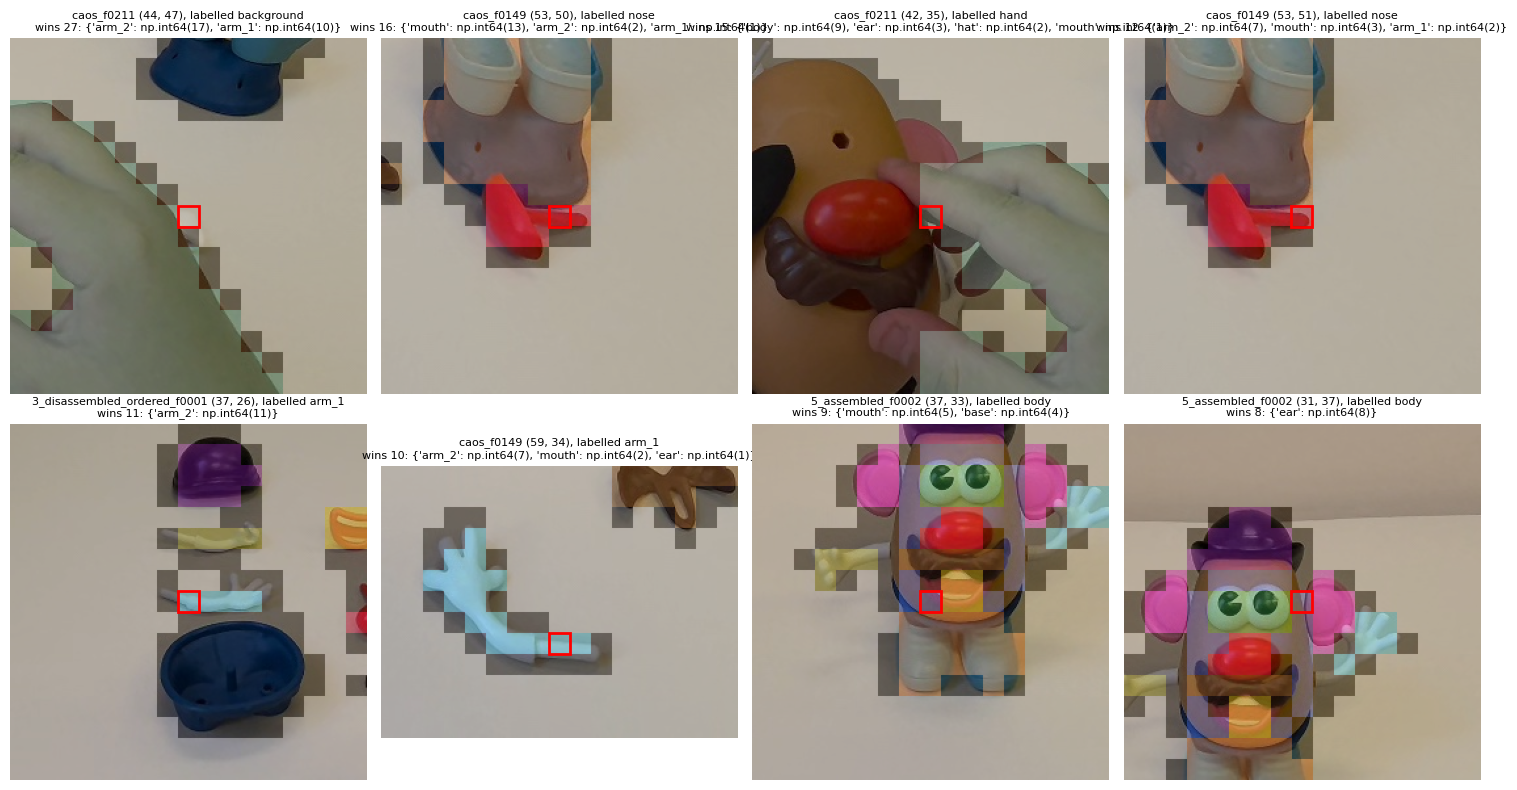

In [28]:
# 8.8 The 8 prototypes of A that win most wrong patches, in their reference frames, with the annotation (description)
from perception.visualization import label_grid_to_rgb

reference_meta = {r["frame"]: r for r in saved["metadata"]["reference_frames"]}
top8 = top.reset_index().head(8)
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, (_, r) in zip(axes.flat, top8.iterrows()):
    meta = reference_meta[r["prototype frame"]]
    with Image.open(FRAMES_DIR / f"{meta['frame']}.jpg") as img:
        size = extractor.input_size(img.width, img.height)
        image = np.asarray(img.convert("RGB").resize(size, Image.Resampling.LANCZOS)).astype(np.float32) / 255
    labels_ref, _ = patch_label_grid(rasterize_annotation(PROJECT_ROOT / meta["annotation"], set(meta["use_labels"]), size),
                                     PATCH_SIZE, MIN_LABEL_COVERAGE)
    colors = cv2.resize(label_grid_to_rgb(labels_ref).astype(np.float32), size, interpolation=cv2.INTER_NEAREST)
    shown = 0.65 * image + 0.35 * colors                                   # annotation in transparency (ignored = dark)

    row, col = int(r["prototype row"]), int(r["prototype col"])
    r0, c0 = max(row - 8, 0), max(col - 8, 0)
    r1, c1 = min(row + 9, labels_ref.shape[0]), min(col + 9, labels_ref.shape[1])
    ax.imshow(shown[r0 * PATCH_SIZE:r1 * PATCH_SIZE, c0 * PATCH_SIZE:c1 * PATCH_SIZE])
    ax.add_patch(mpatches.Rectangle(((col - c0) * PATCH_SIZE - 0.5, (row - r0) * PATCH_SIZE - 0.5), PATCH_SIZE, PATCH_SIZE,
                                    fill=False, edgecolor="red", linewidth=2))
    ax.set_title(f"{meta['frame']} ({row}, {col}), labelled {r['label_A']}\nwins {r['wins']}: {r['pieces_won']}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "culprit_prototypes_A.png", dpi=90, bbox_inches="tight")
plt.show()

Observation 8.7: The 353 patches of assembly_2 that A labels wrongly are won by 116 of its 39,125 prototypes. The 10 most frequent winners take 124 of them (35%), the 20 most frequent 186 (53%). The errors of A are concentrated on very few prototypes.

The largest winner is one background prototype of caos_f0211 (row 44, column 47), which takes 27 patches of the arms, 17 of arm_2 and 10 of arm_1. Two adjacent nose prototypes of caos_f0149 (row 53, columns 50 and 51) take 28 patches, 16 of the mouth and 9 of arm_2. Two hand prototypes of caos_f0211 take 22 patches, 14 of them of the body. Four arm_1 prototypes, two of 3_disassembled_ordered_f0001 and two of caos_f0149, take 32 patches of arm_2. One hat prototype of 2_disassembled_caos_f0016 (row 27, column 32) takes 8 patches of the base. Four prototypes of 5_assembled_f0002, labelled body or base, take patches of the mouth, the ear, the moustache and the body.

By reference frame, caos_f0149 causes most errors, 84 of 353: 47 of the 102 errors on arm_2 and 22 of the 35 on the mouth. It is the frame that gives arm_1 79% of its recognition (support-set study on V2, Observation 8.5). Then come 5_assembled_f0002 (73, mostly body, moustache and ear), caos_f0211 (64, mostly body and the arms), 3_disassembled_ordered_f0001 (45, of which 26 on arm_2), 5_assembled_f0019 (42, mostly body) and 2_disassembled_caos_f0016 (22, hat and base). The other four reference frames cause 23 errors together.

Interpretation, as a hypothesis. caos_f0149 is at the same time the most needed and the most harmful frame of A: its prototypes carry arm_1 and take arm_2 and the mouth. This is the zero-sum effect between the arms seen from the side of the support set. Removing the whole frame would repeat the failure of the support-set study on V2; at most some of its patches could be removed. The frames of the assembled figure cause the errors on the face pieces, which are small and attached to the body.

Observation 8.8: All eight prototypes shown lie on a boundary. The background prototype of caos_f0211 lies on the edge of a hand, just outside its annotated polygon. The two nose prototypes of caos_f0149 lie on the thin stem of the nose, mostly table. The hand prototype of caos_f0211 is a finger touching the nose. The two arm_1 prototypes lie on the tube of the arm, the one of caos_f0149 next to its peg. The two body prototypes of 5_assembled_f0002 lie where the body meets the mouth and the base, and where it meets an ear.

Interpretation, as a hypothesis. The winners are patches that mix two things: a piece and the table, a piece and a hand, two pieces. Only the background patch on the edge of the hand may come from an annotation slightly inside the real contour. This agrees with condensation, which keeps the points near the boundaries between classes (García et al. 2012, Sect. 3.1.2), and it is tested in Section 8.9.

In [29]:
# 8.9 A' = A with caos_f0149 restricted to arm_1 and hand: its other pieces are dropped (description)
# Background patches are never annotated, so they do not change; this equals use_labels = {arm_1, hand} for that frame.
meta = reference_meta["caos_f0149"]
print(f"caos_f0149 in A: role {meta['role']}, use_labels {sorted(meta['use_labels'])}")
KEEP_IN_CAOS = [CLASS_NAMES.index(c) for c in ("background", "arm_1", "hand")]
drop = (ORIGIN["frame"].values == "caos_f0149") & ~np.isin(A_OWNERS, KEEP_IN_CAOS)
print(f"Prototypes removed: {int(drop.sum())}", dict(pd.Series([CLASS_NAMES[c] for c in A_OWNERS[drop]]).value_counts()))

A2_VECTORS, A2_OWNERS = A_VECTORS[~drop], A_OWNERS[~drop]           # still sorted by class
A2_GPU = tuple(torch.as_tensor(x, device=DEVICE) for x in (A2_VECTORS, A2_OWNERS))

# Errors on the candidates of assembly_2, A against A'
S_A2 = torch.as_tensor(class_similarities_gpu(X.cpu().numpy()[:, None, :], *A2_GPU)[:, 0, :], device=DEVICE)
wrong_a2 = S_A2.argmax(dim=1).cpu().numpy() != CAND["class_id"].values
display(pd.DataFrame({"candidates": CAND["class"].value_counts(),
                      "wrong with A": CAND.loc[wrong_a.values, "class"].value_counts(),
                      "wrong with A'": CAND.loc[wrong_a2, "class"].value_counts()}).reindex(PIECES).fillna(0).astype(int).T)
print(f"Wrong patches of assembly_2: A {int(wrong_a.sum())}, A' {int(wrong_a2.sum())}")

# assembly_1, description only
for item in EVAL_FRAMES:
    item["labels"]["A'"] = assign_labels(class_similarities_gpu(item["features"], *A2_GPU), MARGIN)
CONF["A'"] = [confusion_matrix(item["gt"], item["labels"]["A'"]) for item in EVAL_FRAMES]
display(pd.DataFrame({name: frame_iou(CONF[name], EXCLUDED)[PIECE_IDX] for name in ("A", "A'", "G")}, index=PIECES).round(3).T)
print({name: round(frame_miou(CONF[name], EXCLUDED), 3) for name in ("A", "A'", "G")},
      {f"arm_2 hits {name}": int(arm_2_hits(name).sum()) for name in ("A", "A'", "G")})

caos_f0149 in A: role partially assembled, use_labels ['arm_1', 'arm_2', 'base', 'body', 'ear', 'eyes', 'hat', 'moustache', 'mouth', 'nose']
Prototypes removed: 152 {'base': np.int64(59), 'body': np.int64(40), 'moustache': np.int64(12), 'ear': np.int64(11), 'nose': np.int64(10), 'hat': np.int64(8), 'eyes': np.int64(6), 'mouth': np.int64(6)}


class,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2
candidates,1297,784,535,249,295,185,215,129,262,167
wrong with A,83,22,30,7,17,15,23,35,19,102
wrong with A',84,23,30,7,18,18,29,28,17,98


Wrong patches of assembly_2: A 353, A' 352


,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2
A,0.864,0.909,0.905,0.815,0.892,0.721,0.766,0.626,0.733,0.416
A',0.851,0.933,0.910,0.818,0.832,0.792,0.713,0.621,0.716,0.423
G,0.858,0.936,0.888,0.769,0.933,0.811,0.803,0.710,0.727,0.640


{'A': 0.765, "A'": 0.761, 'G': 0.807} {'arm_2 hits A': 35, "arm_2 hits A'": 36, 'arm_2 hits G': 91}


Observation 8.9: In A, caos_f0149 is a frame of the partially assembled figure with all ten pieces in use. Restricting it to arm_1 and hand removes 152 prototypes: base 59, body 40, moustache 12, ear 11, nose 10, hat 8, eyes 6 and mouth 6.

On the candidates of assembly_2, A' labels 352 patches wrongly against 353 for A. The mouth improves (28 errors against 35) and arm_2 slightly (98 against 102), while the moustache (29 against 23), the nose (18 against 15), body, base and ear get worse. On assembly_1 the mIoU of A' is 0.761 against 0.765 for A: the nose rises from 0.721 to 0.792 and the base from 0.909 to 0.933, while the ear falls from 0.892 to 0.832 and the moustache from 0.766 to 0.713. arm_2 is unchanged (36 patches labelled arm_2 against 35), against 91 for G.

Interpretation, as a hypothesis. The prototypes removed are not noisy: each helps some pieces and harms others, so removing them moves the errors between the face pieces instead of removing them. The errors of A come from narrow boundaries between similar classes, not from wrong examples. Hart corrects them by adding examples where they are needed, without removing any; A' is not carried further.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 8:

Phase 1 test, Section 8: the video of assembly_1 labelled frame by frame with A.

Cawley and Talbot 2010, Sect. 5: a choice made on the evaluation data makes its estimate optimistic, which is why the number of patches is described and not chosen here.

García et al. 2012, Sect. 3.1.2: edition removes examples that disagree with their neighbours; condensation keeps the points near the boundaries between classes.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 9 - Blind comparison on a new iPhone recording

The phone is the camera of the coming work, and assembly_1 could not tell a good support set from a bad one (Section 7, Section 8.1). The choice between A, G and H is made here, by eye, on a new recording of a complete assembly, decision.MOV. A second recording made the same day, test.MOV, is not processed here and is kept for the final test.

The comparison is blind. Every frame is labelled by the three support sets, shown side by side as panels X, Y and Z. The assignment of the support sets to the panels is drawn at random and written to a file that is opened by the code only after the scoring sheet is filled and committed.

The criteria are fixed before the video exists. For every piece and every moment of the assembly, each panel scores 1 if the piece carries its own label over at least half of its visible part, and 0 otherwise. The moments are: loose, on the table just before the hand touches it; in hand, from the lift to the insert; mounting, from the insert until the hands leave the figure. The two ears are scored as two events.

The decision follows the rule of Section 1, with scores in place of patches. A candidate, G or H, replaces A only if two conditions hold. First, arm_2 scores more than with A, summed over its three moments. Second, no cell where A scores 1 is scored 0 by the candidate. If both G and H qualify, the one with the higher total is kept, and G on a tie, since it has fewer prototypes. Otherwise A is kept.

The recording contains a few mistakes of assembly, as in real work. For every piece, the moments are those of the episode that ends with the piece mounted: loose is just before the touch of that episode, and earlier picks or mounts that were undone are not scored. A moment that falls outside the central square gets the same score in all three panels, with a note.

In [30]:
# 9.1 iPhone decision video: settings and the blind assignment of the support sets to the panels
import secrets

IPHONE_VIDEO = IPHONE_DIR / "decision.MOV"           # first recording; test.MOV is never processed here
BLIND_DIR = OUTPUT_DIR / "iphone_blind"
BLIND_DIR.mkdir(exist_ok=True)
PANELS = ["X", "Y", "Z"]
KEY_PATH = BLIND_DIR / "key_do_not_open.json"
if not KEY_PATH.exists():                            # drawn once; a rerun keeps the same assignment
    order = ["A", "G", "H"]
    secrets.SystemRandom().shuffle(order)
    KEY_PATH.write_text(json.dumps(dict(zip(PANELS, order))))
KEY = json.loads(KEY_PATH.read_text())               # used by the code, never printed before Section 9.4
print(f"Assignment written, SHA-256 {hashlib.sha256(KEY_PATH.read_bytes()).hexdigest()[:12]}")

Assignment written, SHA-256 f6d2fd173e56


Observation 9.1: The assignment of A, G and H to the panels X, Y and Z is drawn once and written to a file that is not opened before Section 9.4; its SHA-256 begins with f6d2fd173e56. The scoring sheet has 33 empty rows, 11 pieces by 3 moments. Both are fixed, and committed, before decision.MOV is recorded. After the recording and before any scoring, the empty sheet was written again with a semicolon separator, so that it opens correctly in Excel; its rows did not change.

In [32]:
# 9.2 Blind video: every frame (central square, resized to 1024 as in scratch_iphone_scene) in panels X, Y, Z
def iphone_frame(frame_bgr):
    """Central square of a phone frame, resized to the model input with Lanczos."""
    h, w = frame_bgr.shape[:2]
    side = min(h, w)
    square = frame_bgr[(h - side) // 2:(h - side) // 2 + side, (w - side) // 2:(w - side) // 2 + side]
    return Image.fromarray(cv2.cvtColor(square, cv2.COLOR_BGR2RGB)).resize(INPUT_SIZE, Image.Resampling.LANCZOS)


cap = cv2.VideoCapture(str(IPHONE_VIDEO))
assert cap.isOpened(), f"Cannot open {IPHONE_VIDEO}"
fps, n_frames = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"{IPHONE_VIDEO.name}: {n_frames} frames at {fps:.2f} fps, "
      f"{int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))}x{int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))}")
SIDE = 640
writer = cv2.VideoWriter(str(BLIND_DIR / "decision_blind.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), fps, (3 * SIDE, SIDE))
blind_labels = {p: [] for p in PANELS}

start = time.time()
for f in range(n_frames):
    ok, frame_bgr = cap.read()
    if not ok:
        break
    image = iphone_frame(frame_bgr)
    features, size = extractor.extract(image)
    assert tuple(size) == INPUT_SIZE
    rgb = np.asarray(image)
    panels = []
    for p in PANELS:
        labels = assign_labels(class_similarities_gpu(features, *SUPPORT[KEY[p]][2]), MARGIN)
        blind_labels[p].append(labels.astype(np.uint8))
        panel = cv2.resize(render_overlay(rgb, labels, MIN_BLOB_PATCHES), (SIDE, SIDE))
        cv2.putText(panel, f"{p}   {f / fps:.1f} s", (15, 35), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2, cv2.LINE_AA)
        panels.append(panel)
    writer.write(cv2.cvtColor(np.hstack(panels), cv2.COLOR_RGB2BGR))
    if (f + 1) % 300 == 0:
        print(f"{f + 1}/{n_frames} frames, {(time.time() - start) / 60:.1f} min")
cap.release()
writer.release()
np.savez_compressed(BLIND_DIR / "decision_labels_blind.npz", fps=fps, **{p: np.stack(v) for p, v in blind_labels.items()})
print(f"Done: {f + 1} frames in {(time.time() - start) / 60:.0f} min")

decision.MOV: 3872 frames at 29.99 fps, 1920x1080
300/3872 frames, 4.1 min
600/3872 frames, 8.2 min
900/3872 frames, 12.3 min
1200/3872 frames, 16.0 min
1500/3872 frames, 19.8 min
1800/3872 frames, 23.6 min
2100/3872 frames, 27.4 min
2400/3872 frames, 31.1 min
2700/3872 frames, 34.9 min
3000/3872 frames, 38.7 min
3300/3872 frames, 42.4 min
3600/3872 frames, 46.2 min
Done: 3872 frames in 50 min


In [34]:
# 9.3 Scoring sheet: one row per piece and moment, one column per panel (1 = own label on at least half of it, 0 otherwise)
EVENTS = ["base", "body", "mouth", "moustache", "nose", "eyes", "ear (first)", "ear (second)", "arm_1", "arm_2", "hat"]
MOMENTS = ["loose", "in hand", "mounting"]
SHEET_PATH = BLIND_DIR / "scoring_sheet.csv"
if not SHEET_PATH.exists():                          # never overwrite a filled sheet
    pd.DataFrame([{"piece": e, "moment": m, **{p: "" for p in PANELS}, "notes": ""} for e in EVENTS for m in MOMENTS]
                 ).to_csv(SHEET_PATH, index=False, sep=";", encoding="utf-8-sig")
print(f"Scoring sheet: {SHEET_PATH} ({len(EVENTS) * len(MOMENTS)} rows)")

Scoring sheet: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_support_set_hart\iphone_blind\scoring_sheet.csv (33 rows)


In [35]:
# 9.4 Reveal and decision: run only after the scoring sheet is filled and committed
sheet = pd.read_csv(SHEET_PATH, sep=";", encoding="utf-8-sig")
assert sheet[PANELS].notna().all().all() and sheet[PANELS].isin([0, 1]).all().all(), "Fill every cell with 0 or 1 first"
scores = sheet.rename(columns=KEY)
print("Assignment:", KEY)


def qualifies(name):
    """Rule of Section 9: arm_2 scores more than with A, and no cell where A scores 1 is scored 0."""
    arm_2 = scores["piece"] == "arm_2"
    better_arm_2 = scores.loc[arm_2, name].sum() > scores.loc[arm_2, "A"].sum()
    lost = scores[(scores["A"] == 1) & (scores[name] == 0)]
    return better_arm_2, lost


summary = {}
for name in ("G", "H"):
    better, lost = qualifies(name)
    summary[name] = {"arm_2 better": bool(better), "cells lost": len(lost), "total": int(scores[name].sum())}
    if len(lost):
        display(lost[["piece", "moment", "A", name, "notes"]])
summary["A"] = {"total": int(scores["A"].sum())}
display(pd.DataFrame(summary).T)

passing = [n for n in ("G", "H") if summary[n]["arm_2 better"] and summary[n]["cells lost"] == 0]
choice = "A" if not passing else max(passing, key=lambda n: (summary[n]["total"], n == "G"))
print("Decision:", choice)
(BLIND_DIR / "decision.json").write_text(json.dumps({"assignment": KEY, "summary": summary, "decision": choice}, indent=2))

Assignment: {'X': 'G', 'Y': 'H', 'Z': 'A'}


,arm_2 better,cells lost,total
G,False,0,31
H,False,0,31
A,NaN,NaN,29.0


Decision: A


316

Observation 9: The assignment was X = G, Y = H, Z = A. The sheet has 35 rows, with two rows of mounting for the nose and the moustache, the join in the hand and the mounting on the body. Each moment was judged on one frame chosen by the author within the moment; the three panels always show the same frame, so this choice cannot favour any of them.

G and H receive the same score in every row, 31 each, and A receives 29. G and H lose no cell where A scores 1 and gain two: the mouth and the hat in hand. The three rows of arm_2 are identical in the three panels (loose 1, in hand 0, mounting 1), so condition 1 fails for both G and H, and the rule keeps A.

The notes show differences that the scale of 0 and 1 does not record. In hand, both arms show patches of arm_1 and arm_2 with G and H, and no patch with A. With A the mouth in hand is not recognized, the hat in hand is briefly labelled body, and the moustache in hand forms no blob large enough to be named.

Interpretation, as a hypothesis. The scale of 0 and 1 with the threshold of half the visible piece saturates: an arm in hand mixed between arm_1 and arm_2 scores 0, as an arm not recognized at all. This is the same defect found for seen frames in Section 4. Every measure taken in this notebook points the same way, and no measure shows G worse on a piece that matters for Phase 2, but both rules keep A for lack of precision. The decision of Phase 1 stays A. The comparison between A and G moves to the final test on a new annotated recording, with a rule designed beforehand for the precision available.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 9:

Section 1 of this notebook: the decision rule, here applied to scores given by eye.

scratch_iphone_scene.ipynb, Section 2.2: the central square of the phone frame, resized to 1024 with Lanczos.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 10 - Conclusions

The support set of Phase 1 stays A. G, A plus 248 patches of assembly_2 chosen by Hart and reduced by Gates, was judged twice by rules fixed in advance, on assembly_1 and blind on a new iPhone recording, and both rules kept A.

Neither rule found G worse on a piece that matters for Phase 2. On assembly_1, G labelled arm_2 correctly in 91 patches against 35 where it is loose or in hand, lost no event and raised the mIoU from 0.765 to 0.807, but its losses could not be shown smaller than 0.014 on every piece with 31 frames. On the iPhone, G lost no cell and gained two, but the scale of 0 and 1 could not separate an arm mixed between arm_1 and arm_2 from an arm not recognized at all.

Three results carry over. First, Hart and Gates give a general rule to add examples to a support set from a recording of the real procedure, without choosing anything on the evaluation data. Second, the errors of A are concentrated on few prototypes and come from narrow boundaries between similar pieces, not from wrong examples: removing them moves the errors instead of removing them. Third, a rule of decision must be designed for the precision of the data it will use: a margin smaller than the natural variation of a piece, or a scale that saturates, cannot tell a good support set from a bad one.

For Phase 2, the patches of every piece in every frame and state of assembly_1 and the labels of every frame of its video are saved in outputs/phase_1_support_set_hart.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 10:

Hart 1968, p. 515; Gates 1972, p. 432; García et al. 2012, Sect. 3.1.2; Piaggio et al. 2012, eAppendix ("Design").

------------------------------------------------------------------------------------------------------------------------------------------